# 2026 CITS4012 Project
*Make sure you change the file name with your group id.*

## Group and Contributors

- Group ID: 67
- Contributors
  - Ray You (25292965) - Data Pipeline and Models Design
  - Chris Zheng (student ID to be added)
  - Zhihao Zhou (24740212) - designed the experiment plan; implemented and ran all baselines; ran the test-set evaluation

## GitHub

- https://github.com/RayYouDS/cits4012-NLP-project

# Readme
*If there is something to be noted for the marker, please mention here.*

*If you are planning to implement a program with Object Oriented Programming style, please put those the bottom of this ipynb file*

**Notes for the marker**

1. **Run the first code cell (0.1) first.** It clones our GitHub repository (`main` branch) into `/content/repo` and makes it the working directory. All source code is in `scripts/` in that repository, and the notebook imports it from there. The data split, the tokenizer, the training logs and the model checkpoints come from the same clone.
2. **No retraining is needed.** The switches `RUN_E1` (Section 2.2), `RUN_TRAINING` (Sections 2.3 and 2.4) and `RUN_ATTENTION` (Section 3.7) are `False` by default. The notebook then reloads the saved logs, checkpoints and results instead of training:
   - E1 architecture comparison: `scripts/training/e1_stress_results_new_transformer/`
   - E2 main model: `experiments/E2/` (checkpoints in `experiments/E2/checkpoints/`)
   - E4 ablations: `experiments/E4/`
   - Baselines, test predictions and attention analysis: `reports/baselines/`, `reports/test/`, `reports/attention/`
3. Section 3 scores the main model, B1 and B0 again from the saved checkpoints and checks the results against the saved prediction files. B2 and B3 (pretrained models) need a GPU and Hugging Face downloads, so their saved results are read.
4. To retrain, set a switch to `True` and use a Colab GPU runtime. Training is slow: E1 takes about 31 minutes, and each E4 ablation (three seeds) about 50 minutes on a T4.
5. The test set was not used for any choice: the model and all its settings were frozen on the validation set before the test predictions were made. Seeds are 4012, 4013 and 4014. TF32 is turned off in Section 0.4 so that results on an A100 match those on a CPU or a T4.
6. The comments in `scripts/` were translated into English after the experiments were run. Sections 2.3 and 2.4 use git to check that the code behind the saved runs has not changed since; these checks ignore comments and docstrings.

## 0.1 Clone the Repository from GitHub

This step clones the GitHub repository, which contains all files required to run this notebook.

Do NOT run this cell in a local testing environment.

In [1]:
import os, subprocess
from pathlib import Path

# cloning repo to colab
if not Path('/content/repo/.git').exists():
    subprocess.run([
        "git", "clone", "-q", "-b", "main",
        "https://github.com/RayYouDS/cits4012-NLP-project.git", "/content/repo"
    ], check=True)

# Set the working directory to repo root
os.chdir('/content/repo')

## 0.2 Install Required Libraries

Run the following cell to install the dependencies required to run this project in the Google Colab runtime.

In [2]:
!pip install -r requirement.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 5.4 MB/s eta 0:00:00


## 0.3 Import Dependencies

Import most of the libraries required for the subsequent steps in advance.

In [3]:
import gc

import torch
import warnings

import random
import sentencepiece as spm
from pathlib import Path

import pandas as pd
from IPython.display import display

## 0.4 Set Global Variables

Run the following cell to configure the global variables used throughout this notebook.

In [4]:
# ================== Get Device Variable =========================
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    warnings.warn(
        "No GPU runtime detected. Falling back to CPU.",
        RuntimeWarning,
        stacklevel=2
    )

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

# ============= Set PIQA Dataset Base Path ======================
BASE_PATH = Path("./datasets/PIQA")

# =========== Turn off TF32 to ensure A100 compatibility ================
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32 = False

GPU: Tesla T4
Device: cuda
PyTorch: 2.11.0+cu130


# 1.Dataset Processing
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

## 1.1 Load and Clean Raw Data

The `scripts/data_loader/load_piqa_data.py` module handles data loading, conversion from JSONL to DataFrames, and training–validation splitting based on unique goals. It also applies lightweight text normalisation, including:

- Unicode normalisation: Apply NFKC normalisation to standardise compatible Unicode characters.

- Whitespace normalisation: Replace tabs and newline characters with spaces, collapse consecutive whitespace into a single space, and remove leading and trailing whitespace.

Note: PIQA contains short goal descriptions and candidate solutions, where small lexical differences can carry important semantic information. Therefore, stop words (e.g., in, with, and no), punctuation, and original casing are preserved. Stemming, lemmatisation, and other potentially meaning-altering transformations are avoided to minimise the risk of losing information relevant to physical commonsense reasoning.

In [5]:
# Demonstration
from scripts.data_loader.load_piqa_data import clean_piqa_text, piqa_to_dataframe


# Load the raw training data
raw_df = pd.read_json(
    BASE_PATH / "train.jsonl",
    lines=True,
    encoding="utf-8",
)

# Select one example for demonstration
sample = raw_df.iloc[0]

comparison = pd.DataFrame({
    "Field": ["goal", "sol1", "sol2"],
    "Original Text": [
        sample["goal"],
        sample["sol1"],
        sample["sol2"],
    ],
    "Cleaned Text": [
        clean_piqa_text(sample["goal"]),
        clean_piqa_text(sample["sol1"]),
        clean_piqa_text(sample["sol2"]),
    ],
})

display(comparison)

,Field,Original Text,Cleaned Text
0,goal,"When boiling butter, when it's ready, you can","When boiling butter, when it's ready, you can"
1,sol1,Pour it onto a plate,Pour it onto a plate
2,sol2,Pour it into a jar,Pour it into a jar


In [6]:
# clean objects that will not be used to release RAM
del raw_df, comparison, sample

collected = gc.collect()

print(f"Garbage collected: {collected} objects")

Garbage collected: 37 objects


## 1.2 Train the Tokenizer

SentencePiece is adopted as the subword tokenisation framework because it supports language-independent tokenisation and can represent text containing diverse Unicode characters, punctuation, and different casing patterns.

The tokenizer is trained exclusively on the training set to prevent information leakage from the validation and test sets. The resulting tokenizer is then reused consistently across all datasets.

The following special tokens are used to represent sequence boundaries, padding, and unknown tokens.

| Token | ID | Description |
|---|---:|---|
| `<unk>` | 0 | Represents unknown or out-of-vocabulary tokens |
| `<s>` | 1 | Beginning-of-sequence token |
| `</s>` | 2 | End-of-sequence token |
| `<pad>` | 3 | Padding token used to align sequence lengths within a batch |
| `[CLS]` | 4 | Classification token prepended to each input sequence |
| `[SEP]` | 5 | Separator between the goal and candidate solution |

In [7]:
# ================== Load and clean data  ===========================
train_dataset, valid_dataset, test_dataset = piqa_to_dataframe(base_path=BASE_PATH)

# ================= Prepare temporary training corpus for Tokenizer ===========================
temp_corpus = []
temp_corpus.extend(train_dataset['goal'].to_list())
temp_corpus.extend(train_dataset['sol1'].to_list())
temp_corpus.extend(train_dataset['sol2'].to_list())

random.Random(4012).shuffle(temp_corpus)

# =============== Save temp corpus ================================
output_path = Path("./tokenizer")

temp_corpus_path =  output_path / 'temp_piqa_corpus.txt'
with temp_corpus_path.open("w", encoding="utf-8") as f:
    for text in temp_corpus:
        # clean potential returns inside corpus
        text = str(text).replace("\r\n", " ").replace("\n", " ").replace("\r", " ")
        f.write(text + "\n")


# ======================= Train Tokenizer =====================================
model_prefix = output_path / 'piqa_bpe_v3'

spm.SentencePieceTrainer.train(input=str(temp_corpus_path),
                                model_prefix=str(model_prefix),
                                model_type="bpe",

                                vocab_size=8000,
                                character_coverage=1.0,
                                byte_fallback=True,

                                unk_id=0,
                                bos_id=1,
                                eos_id=2,
                                pad_id=3,

                                user_defined_symbols=["[CLS]", "[SEP]"]
                            )

True

In [8]:
# clean objects that will not be used to release RAM
del train_dataset, valid_dataset, test_dataset, temp_corpus, output_path, temp_corpus_path, model_prefix

collected = gc.collect()

print(f"Garbage collected: {collected} objects")

Garbage collected: 0 objects


The following code validates the trained SentencePiece BPE tokenizer through three checks:

- **Subword tokenisation**: Converts a sample sentence containing punctuation, an unseen compound word, a Unicode character with an accent, and an emoji into subword pieces and their corresponding token IDs.

- **Encoding and decoding**: Decodes the generated token IDs back into text to verify that the original sentence can be reconstructed.

- **Special token verification**: Checks the IDs assigned to the unknown, beginning-of-sequence, end-of-sequence, and padding tokens, as well as the custom [CLS] and [SEP] tokens.

These checks help verify that the tokenizer can process diverse text inputs and is configured consistently with the model's input representation.

In [9]:
# ============= Load Global Tokenizer ============================
tokenizer = spm.SentencePieceProcessor(
    model_file="./tokenizer/piqa_bpe_v3.model"
)

In [10]:
# ============== Sentence -> pieces and ids ====================
text = "An unseen-word, café, or 😊 is still tokenizable."

pieces = tokenizer.encode(text, out_type=str)
ids = tokenizer.encode(text, out_type=int)

print('Tokenized Pieces:', pieces)
print('Tokenized IDs:', ids)

Tokenized Pieces: ['▁An', '▁unse', 'en', '-', 'word', ',', '▁c', 'af', 'é', ',', '▁or', '▁', '<0xF0>', '<0x9F>', '<0x98>', '<0x8A>', '▁is', '▁still', '▁to', 'k', 'en', 'iz', 'able', '.']
Tokenized IDs: [3049, 7757, 299, 7930, 5477, 7913, 269, 1421, 7974, 7913, 366, 7890, 246, 165, 158, 144, 377, 1796, 278, 7912, 299, 598, 773, 7911]


In [11]:
# ================ Sentence Restore ==========================
# restore sentence
restored = tokenizer.decode(ids)
print('Restored Sentence:', restored)

Restored Sentence: An unseen-word, café, or 😊 is still tokenizable.


In [12]:
# ================ Test Special Tokens ========================
print("UNK:", tokenizer.unk_id())  # 0
print("BOS:", tokenizer.bos_id())  # 1
print("EOS:", tokenizer.eos_id())  # 2
print("PAD:", tokenizer.pad_id())  # 3

cls_id = tokenizer.piece_to_id("[CLS]")
sep_id = tokenizer.piece_to_id("[SEP]")

print("CLS:", cls_id)
print("SEP:", sep_id)

UNK: 0
BOS: 1
EOS: 2
PAD: 3
CLS: 4
SEP: 5


In [13]:
# clean objects that will not be used to release RAM
del text, pieces, ids, restored, cls_id, sep_id

collected = gc.collect()

print(f"Garbage collected: {collected} objects")

Garbage collected: 0 objects


## 1.3 Prepare Training, Validating, Testing Dataloaders

The `scripts/data_loader/piqa_dataloader.py` module integrates the following components:

- **Tokenisation**: Converts the text fields in the DataFrames into token IDs using the trained SentencePiece tokenizer.

- **Length-based bucketing**: Uses the BucketBatchSampler class to group examples with similar sequence lengths into mini-batches, reducing padding overhead.

- **Dynamic padding and masking**: Pads sequences within each batch to a common length and generates masks to distinguish valid tokens from padding positions.

- **GPU preloading**: Provides preload_dataloader_to_gpu to preload batches onto a specified device, reducing repeated CPU-to-device data transfers when memory permits.

The following code evaluates the padding efficiency achieved by length-based bucketing.

In [14]:
from scripts.data_loader.piqa_dataloader import get_piqa_dataloaders, preload_dataloader_to_gpu

train_loader_bucket, validate_loader_bucket, test_loader_bucket = get_piqa_dataloaders(base_path=BASE_PATH,
                                                                  tokenizer=tokenizer,
                                                                  batch_size=1000,
                                                                  use_bucket=True)

train_loader_no_bucket, validate_loader_no_bucket, test_loader_no_bucket = get_piqa_dataloaders(base_path=BASE_PATH,
                                                                             tokenizer=tokenizer,
                                                                             batch_size=1000,
                                                                             use_bucket=False)

In [15]:
total_tokens = 0
valid_tokens = 0

for input_1, input_2, mask_1, mask_2, labels in train_loader_bucket:
    total_tokens += input_1.numel() + input_2.numel()
    valid_tokens += mask_1.sum().item() + mask_2.sum().item()

padding_ratio = 1 - valid_tokens / total_tokens

print(f"Padding ratio (use bucket): {padding_ratio:.2%}")

total_tokens = 0
valid_tokens = 0

for input_1, input_2, mask_1, mask_2, labels in train_loader_no_bucket:
    total_tokens += input_1.numel() + input_2.numel()
    valid_tokens += mask_1.sum().item() + mask_2.sum().item()

padding_ratio = 1 - valid_tokens / total_tokens

print(f"Padding ratio (not use bucket): {padding_ratio:.2%}")

Padding ratio (use bucket): 34.17%
Padding ratio (not use bucket): 86.64%


Length-based bucketing substantially reduces padding overhead. In our experiment, the padding ratio decreased from 86% without bucketing to 34% with bucketing, a reduction of 52 percentage points. This improves the proportion of valid tokens processed within each mini-batch, although the actual training speedup depends on additional factors such as model architecture and hardware.

The following code tests whether tokenised sentences can be reconstructed through decoding.

In [16]:
input_1, input_2, mask_1, mask_2, labels = next(iter(train_loader_bucket))

text_1 = tokenizer.decode_ids(input_1[0][mask_1[0]].tolist())
text_2 = tokenizer.decode_ids(input_2[0][mask_2[0]].tolist())

print('Restored Text 1:', text_1)
print('Restored Text 2:', text_2)

Restored Text 1: [CLS] how to keep pillows clean[SEP] wash your pillow cases once a week and washing the pillows themselves on a monthly basis, buying antimicrobial zippered pillow protectors can help keep your living room furniture free of any unwanted microscopic guests
Restored Text 2: [CLS] how to keep pillows clean[SEP] wash your pillow cases once a week and washing the pillows themselves on a monthly basis, buying antimicrobial zippered pillow protectors can help keep your bed free of any unwanted microscopic guests


In [17]:
# clean objects that will not be used to release RAM
del train_loader_bucket, validate_loader_bucket, test_loader_bucket
del train_loader_no_bucket, validate_loader_no_bucket, test_loader_no_bucket
del total_tokens, valid_tokens, padding_ratio
del text_1, text_2

collected = gc.collect()

print(f"Garbage collected: {collected} objects")

Garbage collected: 0 objects


# 2. Model Implementation
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

## 2.1 Load Models

This section introduces the recurrent and Transformer-based models used in the PIQA experiments, including their architectures and implementation-specific design choices.

### Recurrent Neural Networks (BiGRU and BiLSTM)

The recurrent models use bidirectional GRU or LSTM layers to encode each goal–solution pair. A single-head self-attention module and masked mean pooling are applied to obtain a fixed-size representation for candidate scoring.

Compared with conventional recurrent text classifiers, these implementations combine bidirectional sequence modelling with an explicit self-attention mechanism to aggregate contextual token representations.

### Transformer Encoder

The Transformer model uses stacked encoder layers with multi-head self-attention and feed-forward networks to contextualise tokens across the input sequence. A sequence-level representation is then extracted using CLS-token pooling or masked mean pooling before candidate scoring.

Unlike the original Transformer architecture, which was introduced for sequence-to-sequence learning with separate encoder and decoder stacks, this implementation uses only the encoder stack because PIQA is formulated as a binary classification task rather than a text-generation task.

### Shared Candidate-Scoring Framework

Both model families encode the two candidate solutions separately and apply a shared linear scoring layer to their representations. The two scores are combined into logits for binary classification, with the training objective based on cross-entropy loss.

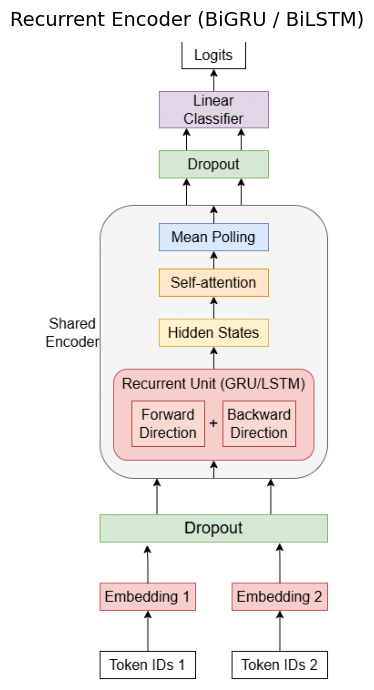

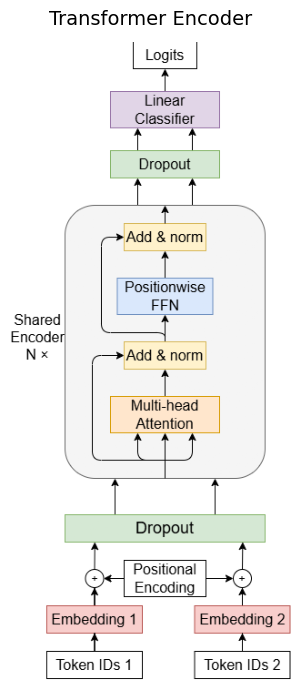

In [18]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display


architecture_diagrams = {
    "Recurrent Encoder (BiGRU / BiLSTM)":
        Path("./docs/figures/rnn_architecture_diagram/rnn_architecture.drawio.png"),
    "Transformer Encoder":
         Path("./docs/figures/transformer_architecture_diagram/transformer_architecture.drawio.png"),
}

for title, image_path in architecture_diagrams.items():
    if not image_path.is_file():
        raise FileNotFoundError(f"Image file not found: {image_path}")

    image = plt.imread(image_path)

    fig, ax = plt.subplots(figsize=(14, 7))
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(title, fontsize=14, pad=12)

    fig.tight_layout()
    display(fig)
    plt.close(fig)

In [19]:
# Load the models
from scripts.models.rnn_attention_refactored import RNNWithAttention
from scripts.models.transformer_bi_classifier import TransformerClassifier

Sections 2.2 to 2.4 are the experiments that support the main model. 2.2 (E1) is the training-budget stress test, which also ranks the three architectures on validation accuracy. 2.3 (E2) is the hyperparameter tuning of the Transformer main model on the validation set. 2.4 (E4) is the ablation training and checks on the frozen main model. Each part reads its saved output by default, and each has a switch to retrain. Section 2.1 above describes the architectures.


## 2.2 E1 — Stress test: GRU vs LSTM vs Transformer

One seed, no early stopping. The point is to see where each validation curve peaks so the team
can fix one training budget for the 3-seed runs. These numbers pick a budget; they are not the
model-comparison result.

**How to use this section.** The default `RUN_E1 = False` shows the saved output of the run described below and trains nothing. Set `RUN_E1 = True` to retrain on a Colab GPU. The saved run took about 31 minutes on an A100 and used Adam, batch 512, seed 4012 only.


In [20]:
RUN_E1 = False          # False (default, for markers): show the saved output. True: retrain on a Colab GPU (about 31 minutes).

### 2.2.1 · Environment

In [21]:
if RUN_E1:
    import torch
    if not torch.cuda.is_available():
        raise SystemExit("No GPU. Runtime > Change runtime type > GPU, then rerun. CPU would take days.")
    print("GPU:", torch.cuda.get_device_name(0))
    print("torch:", torch.__version__)


In [22]:
if RUN_E1:
    import os, subprocess, sys
    from pathlib import Path

    # Guarded: cloning onto an existing directory exits non-zero and check=True would crash.
    if not Path('/content/repo/.git').exists():
        subprocess.run([
            "git", "clone", "-q", "-b", "training-refactor",
            "https://github.com/RayYouDS/cits4012-NLP-project.git", "/content/repo"
        ], check=True)
    os.chdir('/content/repo')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentencepiece'], check=True)

    # run_m3.py resolves everything relative to the repo root, so fail here rather than three
    # cells later with a confusing path error.
    for required in ["scripts/training/run_m3.py", "config/m3_params.json",
                     "scripts/tokenizer/piqa_bpe_v3.model", "datasets/PIQA/train.jsonl"]:
        if not Path(required).is_file():
            raise SystemExit(f"{required} missing — clone failed or the branch moved.")
    COMMIT = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip()
    print('repository commit:', COMMIT)


### 2.2.2 · Results folder

Each run's weights and history are saved only
once it finishes. A disconnect mid-run loses that run, and there is no resume. Drive does not
prevent that, but it keeps the runs that already finished.

In [23]:
if RUN_E1:
    USE_DRIVE = False                  # False -> results live in /content and die with the runtime
    SMOKE_TEST = False                # True -> 3 epochs per run, just to check the pipeline
    RUN_LABEL = "e1_smoke" if SMOKE_TEST else "e1_full"

    from pathlib import Path
    if USE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
        OUT_DIR = Path('/content/drive/MyDrive/cits4012') / RUN_LABEL
    else:
        OUT_DIR = Path('/content') / RUN_LABEL

    # run_m3.py never clears output_dir, so reusing one mixes two experiments' CSVs.
    if OUT_DIR.exists() and any(OUT_DIR.iterdir()):
        raise SystemExit(f"{OUT_DIR} is not empty. Change RUN_LABEL.")
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    print("results ->", OUT_DIR)


### 2.2.3 · Configuration

Everything comes from the committed `config/m3_params.json`; only the output path and the epoch
settings are overridden. The result is written to `/content/`, not into the repository.

In [24]:
if RUN_E1:
    import json, shutil

    MAX_EPOCHS = 1000         # the plan's ceiling for the stress test
    PATIENCE   = None         # no early stopping, per the plan's E1 exception

    with open('config/m3_params.json', encoding='utf-8') as f:
        cfg = json.load(f)
    cfg['output_dir'] = str(OUT_DIR)
    cfg['max_epochs'] = 3 if SMOKE_TEST else MAX_EPOCHS
    cfg['patience']   = PATIENCE

    CONFIG_PATH = '/content/e1_config.json'
    with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
        json.dump(cfg, f, indent=2)

    shutil.copy(CONFIG_PATH, OUT_DIR / 'e1_config.json')   # keep it with the results

    n_runs = len(cfg['models']) * len(cfg['learning_rates']) * len(cfg['seeds'])
    print(json.dumps(cfg, indent=2))
    print(f"\n{len(cfg['models'])} models x {len(cfg['learning_rates'])} lrs x "
          f"{len(cfg['seeds'])} seed = {n_runs} runs x {cfg['max_epochs']} epochs")

### 2.2.4 · Run

Started as a module from the repo root — `run_m3.py` uses absolute package imports.

Each run writes its `*_history.csv`, `*_val_predictions.csv` and `*_best.pt` as soon as it
finishes. The summary, curves and McNemar test come only after all six.

In [25]:
if RUN_E1:
    # -u, and reading the pipe line by line, so the per-epoch lines show up here as they happen instead of sitting in a buffer or going to the kernel log.
    proc = subprocess.Popen(
        [sys.executable, '-u', '-m', 'scripts.training.run_m3', '--config', CONFIG_PATH],
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
    )
    for line in proc.stdout:
        print(line, end='')
    proc.wait()
    if proc.returncode:
        raise SystemExit(f"run_m3 exited with code {proc.returncode}")


### 2.2.5 · Results

**Reading the saved output.** The saved run had 300 epochs per run and ranks GRU 1e-3 first, at validation accuracy 0.5984, against 0.5946 for LSTM 1e-3 and 0.5903 for Transformer 3e-4. GRU and LSTM differ by McNemar p = 0.82, which is not significant. The gap at the best epoch is also smaller for GRU (0.402 against 0.405 for LSTM). Transformer 1e-3 peaked at epoch 282 of 300, so it had not clearly stopped improving.

The code above sets `MAX_EPOCHS = 1000`, but this output was produced with 300 epochs. The budget has to be decided before any rerun.

All numbers come from one seed (4012), so they do not show that one architecture is better than another. E2 then tuned the Transformer as the main model; section 2.3 sets out how it was tuned. This E1 result does not support that choice by itself.

In [26]:
if RUN_E1:
    import pandas as pd
    from IPython.display import Image, display

    # gap_at_best, seconds_to_best and params only appear here, and the plan's decision rule needs all three.
    summary = OUT_DIR / 'm3_summary.csv'
    if summary.exists():
        display(pd.read_csv(summary))
    else:
        print("m3_summary.csv missing - the grid did not finish")

    # valid_accuracy_std is 0.0 on a single seed, meaning not measured. Read n_seeds with it.
    table = OUT_DIR / 'm3_model_table.csv'
    if table.exists():
        display(pd.read_csv(table))

    sel = OUT_DIR / 'm3_selection.json'
    if sel.exists():
        print(json.dumps(json.load(open(sel)), indent=2))


In [27]:
if RUN_E1:
    # Where each curve peaked, and where a patience rule would have stopped. The stress test runs without early stopping, so that epoch has to be read back out of the history — it is what fixes the shared budget for the 3-seed runs.
    import math


    def would_stop_at(acc, patience):
        best, stall = -1.0, 0
        for epoch, a in enumerate(acc, start=1):
            if a > best:
                best, stall = a, 0
            else:
                stall += 1
                if stall >= patience:
                    return epoch
        return None


    rows = []
    for f in sorted(OUT_DIR.glob('*_history.csv')):
        h = pd.read_csv(f)
        acc = h.valid_accuracy.tolist()
        best_ep = int(h.loc[h.valid_accuracy.idxmax(), 'epoch'])
        rows.append({
            'run': f.stem.replace('_history', ''),
            'epochs_run': len(h),
            'best_epoch': best_ep,
            'best_valid': round(max(acc), 4),
            'valid_at_end': round(acc[-1], 4),
            'stop@10': would_stop_at(acc, 10),
            'stop@20': would_stop_at(acc, 20),
            'stop@30': would_stop_at(acc, 30),
            'train_eval_at_end': round(float(h.train_eval_accuracy.iloc[-1]), 4),
            'minutes': round(float(h.epoch_seconds.sum()) / 60, 1),
        })
    plateau = pd.DataFrame(rows)
    display(plateau)

    if len(plateau):
        noise = math.sqrt(0.25 / 1606)
        print(f"1 s.e. on validation accuracy = {noise*100:.2f} pp, so two epochs within about "
              f"{2*noise*100:.1f} pp are a coin flip. best_epoch is not exact.")
        print(f"latest peak across runs: epoch {int(plateau.best_epoch.max())}")
        print("Pick the budget from the curves and the stop@ columns, not from one late peak.")
        print("If any best_epoch is near its epochs_run, that run had not peaked and the test was short.")


In [28]:
if RUN_E1:
    curves = OUT_DIR / 'm3_curves.png'
    if curves.exists():
        display(Image(filename=str(curves)))

,model,learning_rate,seed,best_epoch,epochs_run,valid_accuracy,valid_f1,train_eval_accuracy,gap_at_best,seconds_to_best,seconds_total,params
0,transformer,0.0010,4012,282,300,0.582192,0.582172,1.000000,0.417808,270.92,288.42,999985
1,transformer,0.0003,4012,213,300,0.590286,0.590210,0.988169,0.397883,205.25,288.98,999985
2,gru,0.0010,4012,142,300,0.598381,0.598380,1.000000,0.401619,152.73,322.11,1042001
3,gru,0.0003,4012,158,300,0.592777,0.592701,0.996264,0.403487,169.27,324.61,1042001
4,lstm,0.0010,4012,203,300,0.594645,0.594430,1.000000,0.405355,211.48,311.94,1082401
5,lstm,0.0003,4012,122,300,0.590909,0.590896,0.997509,0.406600,126.32,310.44,1082401


,model,learning_rate,valid_accuracy_mean,valid_accuracy_std,n_seeds
0,gru,0.0010,0.598381,0.0,1
1,lstm,0.0010,0.594645,0.0,1
2,transformer,0.0003,0.590286,0.0,1


{
  "alpha": 0.05,
  "ranking": [
    {
      "model": "gru",
      "learning_rate": 0.001,
      "valid_accuracy_mean": 0.5983810709838107,
      "valid_accuracy_std": 0.0,
      "n_seeds": 1
    },
    {
      "model": "lstm",
      "learning_rate": 0.001,
      "valid_accuracy_mean": 0.5946450809464509,
      "valid_accuracy_std": 0.0,
      "n_seeds": 1
    },
    {
      "model": "transformer",
      "learning_rate": 0.0003,
      "valid_accuracy_mean": 0.5902864259028643,
      "valid_accuracy_std": 0.0,
      "n_seeds": 1
    }
  ],
  "seed": 4012,
  "first": {
    "model": "gru",
    "learning_rate": 0.001
  },
  "second": {
    "model": "lstm",
    "learning_rate": 0.001
  },
  "mcnemar": {
    "only_a": 247,
    "only_b": 241,
    "chi2": 0.05122950819672131,
    "p_value": 0.8209374837557047
  },
  "significant": false
}


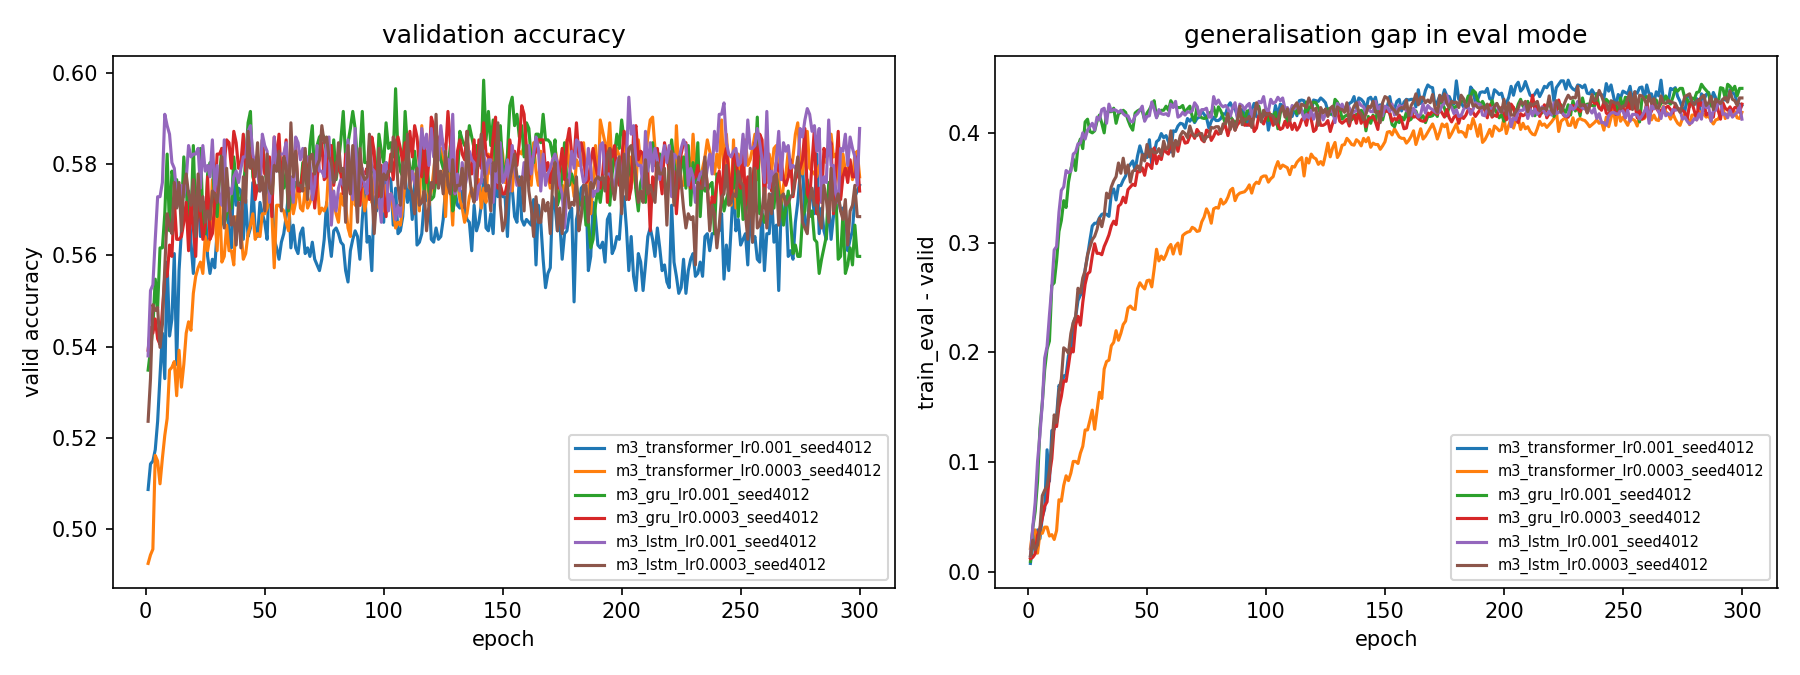

In [29]:
# With RUN_E1 = False the cells above do nothing, so show the saved E1 results from the repository.
if not RUN_E1:
    import json
    import pandas as pd
    from pathlib import Path
    from IPython.display import Image, display

    E1_DIR = Path('scripts/training/e1_stress_results_new_transformer')   # saved run: 300 epochs, seed 4012, Adam, batch 512
    display(pd.read_csv(E1_DIR / 'm3_summary.csv'))
    display(pd.read_csv(E1_DIR / 'm3_model_table.csv'))
    print(json.dumps(json.load(open(E1_DIR / 'm3_selection.json')), indent=2))
    display(Image(filename=str(E1_DIR / 'm3_curves.png')))

### 2.2.6 · Download

In [30]:
if RUN_E1:
    import shutil
    archive = shutil.make_archive('/content/e1_stress_results', 'zip', OUT_DIR)
    print(archive, round(Path(archive).stat().st_size / 1e6, 1), "MB")

    from google.colab import files
    files.download(archive)

## 2.3 E2: Hyperparameter tuning of the main model (validation set)

This notebook records how the main model's hyperparameters were chosen, and shows the saved results.
Every number here comes from files in `results/`, so **you do not need to run the training to check the work**.

**How to read it.** Each stage changes one variable, starts from the previous stage's winner, and uses one seed on the
validation set. The test set is never loaded. The final configuration is re-run on three seeds (4012, 4013, 4014).
The decisions and the reasons for them are in *Stage decisions* below; the limitations are listed after them.

### How to use this section

- **Default (`RUN_TRAINING = False`)**: reads the saved results in `experiments/E2/results/`, and checks the frozen configuration (written in the configuration cell) against the saved final run. No GPU, no Google Drive and no internet are needed. Run from a downloaded or cloned copy of the repository.
- **Training (`RUN_TRAINING = True`)**: the original Colab procedure on a T4 GPU, with results written to Google Drive. The three final seeds took 32.5 minutes in the saved log. It is not needed for marking.
- **Saved outputs**: the tables are written as CSV, the plot as PNG, and the training logs as text files. The trained model weights are in `experiments/E2/checkpoints/`.

### Configuration

All settings that control this section are in the next cell. The main model's values are written out in full
and checked against the saved configuration file in the repository, so the values shown here are the values that were used.

In [31]:
RUN_TRAINING = False          # False (default, for markers): read the saved results. True: retrain on Colab (T4).
STAGE = 'final'               # 1, 2, 3 or 'final'; used only when RUN_TRAINING is True
SMOKE_TEST = False            # True: 3 epochs per run, separate directory (training only)
SEEDS = [4012, 4013, 4014]    # seeds for the final model
MAX_EPOCHS = 300              # budget for every run, no early stopping
EXPECTED_VALID_ROWS = 1606    # size of the validation split; the test split is not used here

# Frozen main model: every setting of the final E2 run (_commit d0268525). Written here, not read from a file.
FROZEN = {
    'tokenizer': 'scripts/tokenizer/piqa_bpe_v3.model', 'models': ['transformer'],
    'learning_rates': [0.0009], 'seeds': [4012, 4013, 4014], 'optimizer': 'adamw',
    'weight_decay': 0.01, 'momentum': 0.9, 'batch_size': 512, 'max_epochs': 300, 'patience': None,
    'grad_clip': None, 'num_workers': 2, 'embedding_dim': 100, 'hidden_size': 100, 'bidirectional': True,
    'enable_attention': True, 'num_heads': 4, 'num_layers': 2, 'dropout_rate': 0.3, 'pooling': 'cls',
    'enable_pos_emb': True, '_commit': 'd0268525b83d7af9f5d5b3a684b6ad8dec00d4d7',
}
# Data split used by these runs (plan section 0): grouped by goal, seed 4012. Record only.
# Train and validation sizes are from the saved log; the test size is from the README and is not used here.
SPLIT = {'method': 'piqa_to_dataframe, grouped by goal, seed 4012', 'train': 14507, 'valid': 1606, 'test': 1838}

In [32]:
if RUN_TRAINING:
    import torch
    if not torch.cuda.is_available():
        raise SystemExit("No GPU. Runtime > Change runtime type > GPU, then rerun.")
    print("GPU:", torch.cuda.get_device_name(0), "|", torch.__version__)

In [33]:
import os, subprocess, sys
from pathlib import Path

if RUN_TRAINING:

    BRANCH = "baselines"
    REPO = Path("/content/repo")

    if not (REPO / '.git').exists():
        subprocess.run(["git", "clone", "-q", "-b", BRANCH,
                        "https://github.com/RayYouDS/cits4012-NLP-project.git",
                        str(REPO)], check=True)
    os.chdir(REPO)

    # A clone left over from an earlier session can sit on a different branch, or on an older commit
    # of the right branch. The branch name alone does not tell you which code is about to run.
    on = subprocess.check_output(['git', 'rev-parse', '--abbrev-ref', 'HEAD'], text=True).strip()
    if on != BRANCH:
        raise SystemExit(f"/content/repo is on {on}, not {BRANCH}. Delete /content/repo and rerun.")

    subprocess.run(['git', 'fetch', '-q', 'origin', BRANCH], check=True)
    local = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip()
    remote = subprocess.check_output(['git', 'rev-parse', 'FETCH_HEAD'], text=True).strip()
    if local != remote:
        behind = subprocess.check_output(
            ['git', 'rev-list', '--count', f'{local}..{remote}'], text=True).strip()
        raise SystemExit(
            f"/content/repo is at {local[:9]} but origin/{BRANCH} is at {remote[:9]} "
            f"({behind} commits ahead). Delete /content/repo and rerun so the run uses current code.")
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentencepiece'], check=True)

    for required in ["scripts/training/run_m3.py",
                     "scripts/tokenizer/piqa_bpe_v3.model", "datasets/PIQA/train.jsonl"]:
        if not Path(required).is_file():
            raise SystemExit(f"{required} missing - clone failed or the branch moved.")

    # Stage 2 compares dropout. Without the wiring every run silently uses 0.1 and the stage
    # would compare three identical models.
    src = Path('scripts/training/run_m3.py').read_text(encoding='utf-8')
    builder = src[src.index('def build_model'):src.index('def build_optimizer')]
    missing = [k for k in ('dropout_rate', 'pooling', 'enable_pos_emb') if k not in builder]
    if missing:
        raise SystemExit(f"build_model does not pass {missing} - this branch predates that wiring.")

    # run_m3 seeds a fresh generator per run, so different seeds do get different batch orders.
    # What preloading removes is the per-epoch reshuffle within a run: the bucket sampler runs once
    # and every epoch then repeats the same batches in the same order.
    if 'preload_dataloader_to_gpu(\n                    train_loader' in src:
        print("NOTE: the training loader is preloaded into a fixed list, so within each run every"
              " epoch sees the same batches in the same order. Seeds still differ from each other.")

    # The commit only describes what runs if nobody edited the checkout. -uno looks at tracked
    # files only, so results written elsewhere and __pycache__ cannot raise a false alarm.
    edited = subprocess.check_output(['git', 'status', '--porcelain', '-uno'], text=True).strip()
    if edited:
        raise SystemExit(f"/content/repo has local edits:\n{edited}\nDelete /content/repo and rerun.")

    COMMIT = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip()
    print('branch:', BRANCH, ' commit:', COMMIT[:9], ' clean working tree')

else:
    # Read mode: find the repository root from the working directory.
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments').is_dir())
    HAS_GIT = (REPO / '.git').exists()
    COMMIT = (subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip()
              if HAS_GIT else 'not recorded (no .git in this copy)')
    print('repository:', REPO, '| commit:', COMMIT[:9] if HAS_GIT else COMMIT)

repository: /content/repo | commit: b102ef9d8


In [34]:
import ast
import json
HAS_GIT = (REPO / '.git').exists()


def git(*args):
    return subprocess.check_output(['git', '-C', str(REPO), *args], text=True).strip()


def code_only(source):
    """The parsed code without its comments and docstrings."""
    tree = ast.parse(source)
    for node in ast.walk(tree):
        if isinstance(node, (ast.Module, ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)):
            first = node.body[0] if node.body else None
            if isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant) and isinstance(first.value.value, str):
                node.body = node.body[1:] or [ast.Pass()]
    return ast.dump(tree)


def code_changes(old, new, paths):
    """Files under paths whose code differs between two commits. The comments in scripts/ were translated
    into English after the runs, so edits to comments and docstrings are not counted as code changes."""
    changed = []
    for line in git('diff', '--name-status', old, new, '--', *paths).splitlines():
        status, *names = line.split('\t')
        path = names[-1]
        if (status == 'M' and path.endswith('.py')
                and code_only(git('show', f'{old}:{path}')) == code_only(git('show', f'{new}:{path}'))):
            continue
        changed.append(path)
    return changed


if not RUN_TRAINING:
    # The saved record of the final run must agree with the settings written in the configuration cell.
    saved_main = json.loads((REPO / 'experiments/E2/results/final_3seed/config.json').read_text(encoding='utf-8'))
    for k, v in FROZEN.items():
        if not k.startswith('_') and k != 'output_dir':
            assert saved_main.get(k) == v, f'{k}: saved run has {saved_main.get(k)}, notebook has {v}'
    assert saved_main['_commit'] == FROZEN['_commit'], 'saved run commit differs from the notebook'
    print('frozen configuration matches the saved final run (final_3seed/config.json)')


frozen configuration matches the saved final run (final_3seed/config.json)


### Where results go

A run is saved only once it finishes; a disconnect loses the run in flight and there is no resume.
Later stages read earlier stages' results off disk, so losing them means starting over.

### Configuration

Each run's config is copied next to its results as `config.json`, so a later stage reads the
winning configuration from disk instead of having it typed in again.

The stage winners are chosen by the rules in *Stage decisions*. `PICK` records the one choice that overrides the
highest-validation rule, so the decision stays visible in the notebook.

In [35]:
from pathlib import Path
if RUN_TRAINING:
    from google.colab import drive
    drive.mount('/content/drive')
    RUN_TAG = 'e2_smoke_300' if SMOKE_TEST else 'e2_full_300'
    OUT_ROOT = Path('/content/drive/MyDrive/cits4012') / RUN_TAG
else:
    OUT_ROOT = REPO / 'experiments/E2/results'
OUT_ROOT.mkdir(parents=True, exist_ok=True)
print("results root ->", OUT_ROOT)

results root -> /content/repo/experiments/E2/results


In [36]:
import json, shutil
import pandas as pd

# Embedded so this runs against the shared branch with nothing pushed first.
BASE = {   'output_dir': 'reports/e2_base',
    'tokenizer': 'scripts/tokenizer/piqa_bpe_v3.model',
    'models': ['transformer'],
    'learning_rates': [0.0003],
    'seeds': [4012],
    'optimizer': 'adam',
    'weight_decay': None,
    'momentum': 0.9,
    'batch_size': 512,
    'max_epochs': 300,
    'patience': None,
    'grad_clip': None,
    'num_workers': 2,
    'embedding_dim': 100,
    'hidden_size': 100,
    'bidirectional': True,
    'enable_attention': True,
    'num_heads': 4,
    'num_layers': 3,
    'dropout_rate': 0.1,
    'pooling': 'cls',
    'enable_pos_emb': True}


def finished(prefixes):
    """(config, summary row) for every finished run whose directory starts with any prefix."""
    if isinstance(prefixes, str):
        prefixes = (prefixes,)
    out = []
    seen = set()
    for d in sorted(d for prefix in prefixes for d in OUT_ROOT.glob(prefix + '*')):
        if d.name in seen:
            continue
        seen.add(d.name)
        summary, config = d / 'm3_summary.csv', d / 'config.json'
        if summary.is_file() and config.is_file():
            cfg = json.load(open(config, encoding='utf-8'))
            for _, row in pd.read_csv(summary).iterrows():
                out.append((d.name, cfg, row))
    return out


# best() ranks by validation accuracy. When McNemar says the top two are a tie, the plan's rule
# is to pick by overfitting gap, then time to best, then parameter count - which best() cannot do
# for you. Record that choice here, keyed by the stage it applies to, rather than deleting
# directories to force the outcome. The chosen directory is written into the next stage's config
# as _from, so the decision stays visible afterwards.
PICK = {
    3: 's2_dropout0.3',
    'final': 's3_layers2',

}


def best(prefixes):
    runs = finished(prefixes)
    if not runs:
        raise SystemExit(f"no finished results under {OUT_ROOT}/{prefixes} - run that stage first.")
    ranked = sorted(runs, key=lambda r: r[2].valid_accuracy, reverse=True)
    chosen = PICK.get(STAGE)
    if chosen:
        match = [r for r in ranked if r[0] == chosen]
        if not match:
            raise SystemExit(f"PICK[{STAGE}] = {chosen!r} is not a finished run under {prefixes}. "
                             f"Available: {[r[0] for r in ranked]}")
        if match[0] is not ranked[0]:
            print(f"PICK[{STAGE}]: using {chosen} instead of the highest validation accuracy "
                  f"({ranked[0][0]}, {ranked[0][2].valid_accuracy:.4f}).")
        ranked = match + [r for r in ranked if r[0] != chosen]
    name, cfg, row = ranked[0]
    print(f"best of {prefixes}: {name}  {cfg['optimizer']} lr={row.learning_rate:g} "
          f"dropout={cfg['dropout_rate']} layers={cfg['num_layers']} -> valid {row.valid_accuracy:.4f}")
    # The margin matters here, not three cells later: this winner is what the next stage builds on.
    if len(ranked) > 1:
        margin = row.valid_accuracy - ranked[1][2].valid_accuracy
        runner = ranked[1]
        print(f"  runner-up {runner[0]} at {runner[2].valid_accuracy:.4f}, margin {margin*100:.2f} pp")
        if margin < 0.0125:
            print("  margin is small. The results cell runs McNemar on these two; if that comes out"
                  " non-significant, the plan's E1 rule says to prefer the smaller overfitting gap,"
                  " then the shorter time, then fewer parameters, and to record the choice.")
    # The learning rate comes from the row (a stage sweeps several); everything else from its config.
    keep = {k: cfg[k] for k in ('optimizer', 'weight_decay', 'momentum',
                                'dropout_rate', 'num_layers', 'num_heads')}
    keep['learning_rates'] = [float(row.learning_rate)]
    keep['_from'] = name
    return keep


def job(name, **overrides):
    cfg = dict(BASE)
    cfg['seeds'] = [4012]
    cfg['output_dir'] = str(OUT_ROOT / name)
    cfg.update(overrides)
    if SMOKE_TEST:
        cfg['max_epochs'] = 3
    return name, cfg


if STAGE == 1:
    # The plan's grid: E1's best learning rate divided by 3, itself, and times 3.
    lr = BASE['learning_rates'][0]
    GRID = [float(f'{x:.2g}') for x in (lr / 3, lr, lr * 3)]
    print('learning rates:', GRID)
    # One learning rate per invocation. run_m3 writes m3_summary.csv only after every run in
    # a config finishes, so a disconnect part way through a three-rate config throws away the
    # rates that already finished. One rate per directory costs a little startup and keeps them.
    JOBS = []
    for optimizer, grid, decay in (('adam', GRID, None),
                                   ('adamw', GRID, 0.01),
                                   ('sgd', [0.01, 0.03, 0.1], None)):
        for rate in grid:
            JOBS.append(job(f's1_{optimizer}_lr{rate:g}', optimizer=optimizer,
                            learning_rates=[rate], weight_decay=decay))

elif STAGE == 2:
    keep = best('s1_')
    # 0.1 is already covered by stage 1.
    JOBS = [job(f's2_dropout{d}', **{**keep, 'dropout_rate': d}) for d in (0.0, 0.3)]

elif STAGE == 3:
    # Stage 2 only ran dropout 0.0 and 0.3 because 0.1 is the stage 1 winner. Looking at s2_ alone
    # would throw that candidate away, so stage 3 starts from the best of stage 1 and stage 2.
    keep = best(('s1_', 's2_'))
    # Depth, not head count: head count leaves the parameter total unchanged, so the plan's
    # "fewer parameters" tie-break cannot separate 2 heads from 4.
    JOBS = [job('s3_layers2', **{**keep, 'num_layers': 2})]

elif STAGE == 'final':
    keep = best(('s1_', 's2_', 's3_'))
    name, cfg = job('final_3seed', **keep)
    cfg['seeds'] = [4012, 4013, 4014]
    JOBS = [(name, cfg)]

else:
    raise SystemExit(f"STAGE must be 1, 2, 3 or 'final', got {STAGE!r}")


PLAN = []
UNVERIFIED = []
for name, cfg in JOBS:
    cfg['_commit'] = COMMIT
    out = Path(cfg['output_dir'])
    if (out / 'm3_summary.csv').is_file():
        # Reusing a finished directory is only safe if it was produced by this exact plan.
        old = json.load(open(out / 'config.json', encoding='utf-8'))
        # Underscore keys are metadata. A key absent from one side falls back to the model's
        # default, so writing pooling='cls' explicitly does not invalidate an earlier run that
        # relied on the same default.
        defaults = {'pooling': 'cls', 'enable_pos_emb': True,
                    'include_goal': True, 'dropout_rate': 0.1}
        differs = sorted(k for k in set(old) | set(cfg)
                         if not k.startswith('_') and k != 'output_dir'
                         and old.get(k, defaults.get(k)) != cfg.get(k, defaults.get(k)))
        if differs:
            raise SystemExit(f"{out} is finished but its config differs on {differs}. "
                             f"Move or delete that directory, or revert the change.")
        old_commit = old.get('_commit')
        if old_commit is None:
            UNVERIFIED.append(name)
        elif old_commit != COMMIT and not HAS_GIT:
            print(f"  {name}: produced at {old_commit[:9]}; no .git in this copy, so the code check is skipped")
        elif old_commit != COMMIT:
            # A different commit only matters if it changed code this experiment runs. Baseline
            # scripts and documentation move independently and must not invalidate results, and
            # code_changes (defined above) does not count edits to comments and docstrings.
            touched = code_changes(old_commit, COMMIT,
                                   ['scripts/training/', 'scripts/models/', 'scripts/data_loader/',
                                    'scripts/evaluation/', 'scripts/tokenizer/', 'datasets/'])
            if touched:
                raise SystemExit(
                    f"{out} was produced at {old_commit[:9]}, and {COMMIT[:9]} changes code it "
                    f"depends on: {touched}. Move or delete that directory and rerun.")
            print(f"  {name}: produced at {old_commit[:9]}, reused - the difference to "
                  f"{COMMIT[:9]} is in comments, docstrings or files this experiment does not run")
        print(f"skip {name} - already finished")
        continue
    # config.json is written here before the run starts, so a directory holding only that has
    # not been used yet and re-running this cell is harmless. Anything else without a summary
    # is a run that died part way: skipping it would hide the gap, reusing the directory would
    # mix two attempts.
    leftovers = sorted(p.name for p in out.glob('*') if p.name != 'config.json') if out.exists() else []
    if leftovers:
        raise SystemExit(f"{out} holds {leftovers[:4]} but no m3_summary.csv - a run died there. "
                         f"Delete that directory, then rerun this cell.")
    out.mkdir(parents=True, exist_ok=True)
    path = f'/content/e2_{name}.json'
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(cfg, f, indent=2)
    shutil.copy(path, out / 'config.json')
    PLAN.append((name, path, cfg))
    print(f"  {name:16s} {cfg['optimizer']:6s} lr={cfg['learning_rates']} "
          f"dropout={cfg['dropout_rate']} layers={cfg['num_layers']} seeds={cfg['seeds']}")

if UNVERIFIED:
    print(f"\nWARNING: {UNVERIFIED} carry no _commit, so the code that produced them cannot be"
          f" checked against {COMMIT[:9]}. They were written before this notebook started"
          f" recording it. Delete and rerun them if you want that guarantee.")

if PLAN and not RUN_TRAINING:
    raise SystemExit(f"{len(PLAN)} run(s) are not in results/ ({[n for n, _, _ in PLAN]}). "
                     "Read mode cannot train them: copy the saved folders, or set RUN_TRAINING = True on Colab.")
if RUN_TRAINING:
    n_runs = sum(len(c['learning_rates']) * len(c['seeds']) for _, _, c in PLAN)
    print(f"\nstage {STAGE}: {n_runs} runs to train, about {n_runs * 10.7:.0f} min on a T4 (3 seeds took 32.5 min in the saved log)")
else:
    print(f"\nstage {STAGE}: all runs are already in results/. Nothing to train.")

PICK[final]: using s3_layers2 instead of the highest validation accuracy (s1_adamw_lr0.0009, 0.6090).
best of ('s1_', 's2_', 's3_'): s3_layers2  adamw lr=0.0009 dropout=0.3 layers=2 -> valid 0.6040
  runner-up s1_adamw_lr0.0009 at 0.6090, margin -0.50 pp
  margin is small. The results cell runs McNemar on these two; if that comes out non-significant, the plan's E1 rule says to prefer the smaller overfitting gap, then the shorter time, then fewer parameters, and to record the choice.
  final_3seed: produced at d0268525b, reused - the difference to b102ef9d8 is in comments, docstrings or files this experiment does not run
skip final_3seed - already finished

stage final: all runs are already in results/. Nothing to train.


### Stage decisions

| Stage | Variable | Candidates | Winner | Why (validation set) |
|---|---|---|---|---|
| 1 | Optimiser and learning rate | Adam, AdamW, SGD; 9 runs, one seed | AdamW, lr 9e-4 | Highest validation accuracy, 0.6090. Its runner-up Adam 9e-4 (0.6021) is not significantly different (McNemar χ² = 0.297, p = 0.586). The tie rule favours AdamW 9e-4: smaller gap (0.389 vs 0.398), shorter time to best (153 vs 233). |
| 2 | Dropout | 0.0, 0.1 (stage 1), 0.3 | 0.3 | Dropout 0.1 (0.6090) and 0.3 (0.5971) differ by 1.19 pp, not significant (χ² = 0.694, p = 0.405). The tie rule picks 0.3 because its overfitting gap is smaller (0.298 vs 0.389). Recorded as `PICK[3]`. |
| 3 | Depth | 2 and 3 layers | 2 layers | 2 layers: 0.6040, gap 0.295, 933,357 parameters. 3 layers: 0.5971, gap 0.298. The gap difference is 0.003, well below the noise, so this decision is weakly supported. McNemar on the same 1,606 validation questions: χ² = 0.287, p = 0.593, not significant (stage 3 check below). The tie rule then decides on the gap (0.295 vs 0.298) and parameter count (933,357 vs 999,985). Time to best is 203 vs 204 epochs, a tie. |
| Final | Three seeds | 4012, 4013, 4014 | the stage 3 winner | Validation accuracy at the best epoch 0.5940 ± 0.0081 (sample s.d.); plateau mean 0.5797. |

**Override.** Ranking the stage 1–3 runs by validation accuracy alone would choose the stage 1 configuration
(AdamW 9e-4, dropout 0.1, 3 layers, 0.6090). That configuration is not on the staged path, because stage 2 chose dropout 0.3. The override `PICK['final'] = 's3_layers2'` keeps the decisions consistent. The override pair differ by 0.50 pp, McNemar χ² = 0.099, p = 0.753 (not significant), so the choice rests on the tie rule, not on accuracy.

### Run (training only)

Skipped when `RUN_TRAINING = False`. Each run's output is written to `results/<run>/logs/`.

In [37]:
import time
if not RUN_TRAINING:
    print("Training skipped (RUN_TRAINING = False). The saved results are read in the next sections.")
else:
    LOG_DIR = OUT_ROOT / 'logs'
    LOG_DIR.mkdir(exist_ok=True)
    for name, path, cfg in PLAN:
        started = time.time()
        log_path = LOG_DIR / f'{name}.log'
        proc = subprocess.Popen(
            [sys.executable, '-u', '-m', 'scripts.training.run_m3', '--config', path],
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
        )
        with open(log_path, 'w', encoding='utf-8') as log:
            for line in proc.stdout:
                log.write(line)
        proc.wait()
        if proc.returncode:
            raise SystemExit(f"{name} exited with code {proc.returncode}; see {log_path}")
        print(f"{name} done in {(time.time() - started) / 60:.1f} min; log: {log_path}")

Training skipped (RUN_TRAINING = False). The saved results are read in the next sections.


### Results (all runs)

One row per run, sorted by validation accuracy at the best epoch. `plateau_mean` is the mean over the second half of training. Saved to `e2_stage_table.csv`.

In [38]:
import math

runs = finished('')
if not runs:
    print("nothing finished yet")
else:
    rows = []
    for name, cfg, row in runs:
        # valid_accuracy is the best validation accuracy over all epochs
        # plateau_mean averages the second half of the same curve as a second opinion.
        run_id = f"m3_{row.model}_lr{row.learning_rate:g}_seed{int(row.seed)}"
        hist = OUT_ROOT / name / f"{run_id}_history.csv"
        if hist.is_file():
            curve = pd.read_csv(hist).valid_accuracy
            plateau = round(float(curve.iloc[len(curve) // 2:].mean()), 4)
        else:
            plateau = None
        rows.append({'_pred': str(OUT_ROOT / name / f"{run_id}_val_predictions.csv"),
                     'stage': name, 'optimizer': cfg['optimizer'],
                     'lr': row.learning_rate, 'weight_decay': cfg['weight_decay'],
                     'dropout': cfg['dropout_rate'], 'layers': cfg['num_layers'],
                     'heads': cfg['num_heads'], 'seed': int(row.seed),
                     'best_epoch': int(row.best_epoch), 'epochs_run': int(row.epochs_run),
                     'valid': round(row.valid_accuracy, 4),
                     'plateau_mean': plateau, 'gap': round(row.gap_at_best, 3),
                     'params': int(row.params)})
    table = pd.DataFrame(rows).sort_values('valid', ascending=False).reset_index(drop=True)
    display(table.drop(columns=['_pred']))
    table.drop(columns=['_pred']).to_csv(OUT_ROOT / 'e2_stage_table.csv', index=False)

    # sqrt(0.25/1606) = 1.25 pp is the standard error of a single accuracy, not of the paired
    # difference between two models scored on the same 1606 questions. It is a rough yardstick
    # only. McNemar on the two prediction files is the test the plan actually specifies.
    print(f"Rough yardstick: 1 s.e. on a single accuracy = {math.sqrt(0.25/1606)*100:.2f} pp "
          f"(n = 1606). Not a paired test.")

    if len(table) > 1:
        top, second = table.iloc[0], table.iloc[1]
        print(f"Top two differ by {(top.valid - second.valid)*100:.2f} pp "
              f"({top.stage} vs {second.stage}).")
        try:
            try:
                from scripts.evaluation.evaluate import mcnemar_test
            except ImportError:   # scripts/ not on the path: same continuity-corrected test, computed here
                import math
                def mcnemar_test(a, b):
                    only_a = int((a & ~b).sum()); only_b = int((~a & b).sum())
                    chi2 = (abs(only_a - only_b) - 1) ** 2 / (only_a + only_b)
                    return {'only_a': only_a, 'only_b': only_b, 'chi2': chi2,
                            'p_value': math.erfc(math.sqrt(chi2 / 2))}
            a = pd.read_csv(top._pred)[['row_id', 'correct']]
            b = pd.read_csv(second._pred)[['row_id', 'correct']]
            merged = a.merge(b, on='row_id', suffixes=('_a', '_b'))
            result = mcnemar_test(merged.correct_a.to_numpy().astype(bool),
                                  merged.correct_b.to_numpy().astype(bool))
            verdict = 'significant' if result['p_value'] < 0.05 else 'NOT significant'
            print(f"McNemar on the same {len(merged)} questions: only_a={result['only_a']} "
                  f"only_b={result['only_b']} chi2={result['chi2']:.3f} p={result['p_value']:.4f}"
                  f"  -> {verdict} at alpha 0.05")
            if result['p_value'] >= 0.05:
                print("The plan's E1 rule for a tie: prefer the smaller overfitting gap, then the"
                      " shorter time to best, then fewer parameters. Record which one you applied.")
        except Exception as exc:
            print(f"McNemar skipped: {exc}")
    if table.plateau_mean.notna().any() and table.sort_values(
            'plateau_mean', ascending=False).index[0] != 0:
        print("best_epoch and plateau_mean disagree about the winner - this stage separated nothing.")

,stage,optimizer,lr,weight_decay,dropout,layers,heads,seed,best_epoch,epochs_run,valid,plateau_mean,gap,params
0,s1_adamw_lr0.0009,adamw,0.0009,0.01,0.1,3,4,4012,153,300,0.6090,0.5862,0.389,999985
1,s3_layers2,adamw,0.0009,0.01,0.3,2,4,4012,203,300,0.6040,0.5877,0.295,933357
2,s1_adam_lr0.0009,adam,0.0009,NaN,0.1,3,4,4012,233,300,0.6021,0.5876,0.398,999985
3,final_3seed,adamw,0.0009,0.01,0.3,2,4,4012,213,300,0.5996,0.5874,0.290,933357
4,s1_adamw_lr0.0003,adamw,0.0003,0.01,0.1,3,4,4012,296,300,0.5996,0.5875,0.394,999985
5,final_3seed,adamw,0.0009,0.01,0.3,2,4,4013,179,300,0.5978,0.5805,0.268,933357
6,s1_sgd_lr0.1,sgd,0.1000,NaN,0.1,3,4,4012,191,300,0.5971,0.5718,0.359,999985
7,s2_dropout0.3,adamw,0.0009,0.01,0.3,3,4,4012,204,300,0.5971,0.5793,0.298,999985
8,s1_adam_lr0.0003,adam,0.0003,NaN,0.1,3,4,4012,295,300,0.5922,0.5773,0.400,999985
9,s1_adam_lr0.0001,adam,0.0001,NaN,0.1,3,4,4012,116,300,0.5897,0.5741,0.195,999985


Rough yardstick: 1 s.e. on a single accuracy = 1.25 pp (n = 1606). Not a paired test.
Top two differ by 0.50 pp (s1_adamw_lr0.0009 vs s3_layers2).
McNemar on the same 1606 questions: only_a=251 only_b=243 chi2=0.099 p=0.7528  -> NOT significant at alpha 0.05
The plan's E1 rule for a tie: prefer the smaller overfitting gap, then the shorter time to best, then fewer parameters. Record which one you applied.
best_epoch and plateau_mean disagree about the winner - this stage separated nothing.


**Stage 3 tie check.** The 2-layer and 3-layer models differ by 0.68 pp on validation accuracy. This cell tests whether that difference is significant, with the same McNemar test as the stage 1–2 comparisons. It reads the two saved prediction files and does not train.

In [39]:
# Stage 3 tie check: 2 layers against 3 layers, both dropout 0.3, validation set, seed 4012.
# Reads the two saved prediction files only. No training.
try:
    from scripts.evaluation.evaluate import mcnemar_test
except ImportError:   # scripts/ not on the path: same continuity-corrected test, computed here
    import math
    def mcnemar_test(a, b):
        only_a = int((a & ~b).sum()); only_b = int((~a & b).sum())
        chi2 = (abs(only_a - only_b) - 1) ** 2 / (only_a + only_b)
        return {'only_a': only_a, 'only_b': only_b, 'chi2': chi2, 'p_value': math.erfc(math.sqrt(chi2 / 2))}

def load_correct(folder):
    frame = pd.read_csv(OUT_ROOT / folder / 'm3_transformer_lr0.0009_seed4012_val_predictions.csv')
    correct = frame['correct']
    if correct.dtype != bool:
        correct = correct.astype(str).str.lower().isin(['true', '1'])
    return frame[['row_id', 'label']].assign(correct=correct.to_numpy())

two = load_correct('s3_layers2')
three = load_correct('s2_dropout0.3')
pair = two.merge(three, on='row_id', suffixes=('_2', '_3'))
assert len(pair) == EXPECTED_VALID_ROWS, len(pair)
assert (pair.label_2 == pair.label_3).all(), 'labels differ between the two runs'
c2 = pair.correct_2.to_numpy(dtype=bool)
c3 = pair.correct_3.to_numpy(dtype=bool)
res = mcnemar_test(c2, c3)
print(f"accuracy: 2 layers {c2.mean():.4f} | 3 layers {c3.mean():.4f} | difference {100*(c2.mean()-c3.mean()):.2f} pp")
print(f"McNemar on {len(pair)} questions: only 2 layers right = {res['only_a']}, "
      f"only 3 layers right = {res['only_b']}, chi2 = {res['chi2']:.3f}, p = {res['p_value']:.4f}")
print('not significant at alpha 0.05: the tie rule decides (gap, then time to best, then parameters)'
      if res['p_value'] >= 0.05 else 'significant at alpha 0.05')


accuracy: 2 layers 0.6040 | 3 layers 0.5971 | difference 0.68 pp
McNemar on 1606 questions: only 2 layers right = 180, only 3 layers right = 169, chi2 = 0.287, p = 0.5925
not significant at alpha 0.05: the tie rule decides (gap, then time to best, then parameters)


### Training curves (from the saved logs)

Plotted from the per-epoch history files in `results/final_3seed/`, not from a DataFrame held in memory, so the figure can be redrawn from the repository alone.

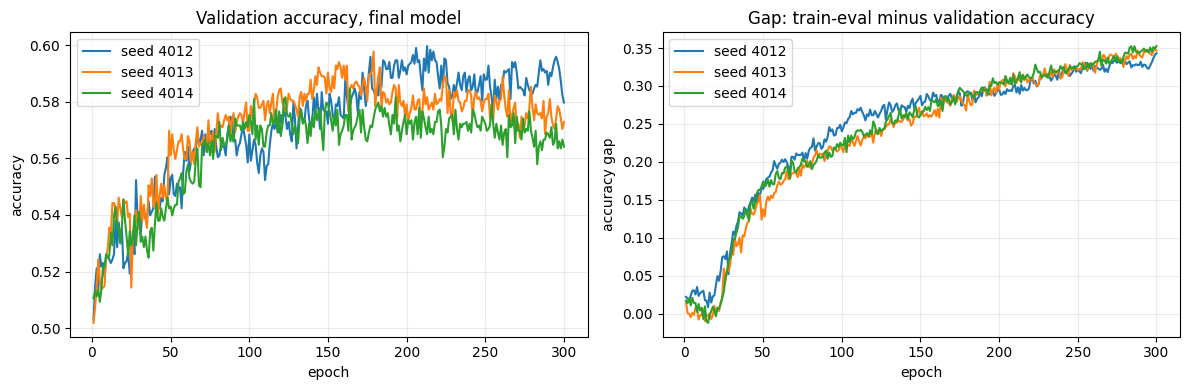

In [40]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for seed in SEEDS:
    h = pd.read_csv(OUT_ROOT / 'final_3seed' / f'm3_transformer_lr0.0009_seed{seed}_history.csv')
    axes[0].plot(h['epoch'], h['valid_accuracy'], label=f'seed {seed}')
    axes[1].plot(h['epoch'], h['train_eval_accuracy'] - h['valid_accuracy'], label=f'seed {seed}')
axes[0].set(title='Validation accuracy, final model', xlabel='epoch', ylabel='accuracy')
axes[1].set(title='Gap: train-eval minus validation accuracy', xlabel='epoch', ylabel='accuracy gap')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT_ROOT / 'e2_final_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Trained model (state_dict)

The three final checkpoints are in `experiments/E2/checkpoints/`. Each file is a PyTorch `state_dict` (saved by `run_m3.py` with `torch.save(model.state_dict(), ...)`), so it loads into a model built with the same settings, without retraining.

The next cell rebuilds the model from the frozen configuration, loads seed 4012, and recomputes its validation accuracy. The result should match `m3_summary.csv` (0.599626 for seed 4012). **This cell needs the repository code (`scripts/`) and the PIQA data (`datasets/PIQA/`), so it runs in a full copy of the repository. It was run in a clean copy of the repository (CPU, PyTorch 2.14), and it reproduced 0.599626.**

In [41]:
import warnings
warnings.filterwarnings('ignore')   # library warnings (nested tensors, shuffle) are not results
import sys, torch, sentencepiece as spm
sys.path.insert(0, str(REPO))                       # relative imports from the repository root
from scripts.models.transformer_bi_classifier import TransformerClassifier
from scripts.data_loader.piqa_dataloader import PIQACollator, tokenize_piqa_dataframe, preload_dataloader_to_gpu
from scripts.training.run_m3 import make_loader
# Importing run_m3 switches matplotlib to the Agg backend, which hides every later plot. Switch back.
%matplotlib inline
from scripts.evaluation.evaluate import evaluate

tokenizer = spm.SentencePieceProcessor(model_file=str(REPO / 'scripts/tokenizer/piqa_bpe_v3.model'))
model = TransformerClassifier(                      # the frozen settings from the configuration cell
    vocab_size=tokenizer.get_piece_size(), embedding_dim=FROZEN['embedding_dim'], padding_idx=tokenizer.pad_id(),
    max_seq_length=2048, num_heads=FROZEN['num_heads'], num_layers=FROZEN['num_layers'],
    dropout_rate=FROZEN['dropout_rate'], enable_pos_emb=FROZEN['enable_pos_emb'], pooling=FROZEN['pooling'])
ckpt = REPO / 'experiments/E2/checkpoints/m3_transformer_lr0.0009_seed4012_best.pt'
model.load_state_dict(torch.load(ckpt, map_location='cpu'))   # strict: fails if the architecture differs
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
model.eval()

_, valid_df, _ = tokenize_piqa_dataframe(REPO / 'datasets/PIQA', tokenizer)
valid_df = valid_df.reset_index(drop=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batches = preload_dataloader_to_gpu(make_loader(valid_df, PIQACollator(tokenizer), 512, 0, False, shuffle=False), device)
metrics, _ = evaluate(model, batches, device)
saved = pd.read_csv(OUT_ROOT / 'final_3seed' / 'm3_summary.csv').set_index('seed')['valid_accuracy'][4012]
print(f"loaded accuracy {metrics['accuracy']:.6f} | saved {saved:.6f} | difference {abs(metrics['accuracy'] - saved):.6f}")

loaded accuracy 0.599626 | saved 0.599626 | difference 0.000000


### Environment and data

- **Data**: goal-grouped split, seed 4012, tokenizer `piqa_bpe_v3.model` (vocabulary 8,000). Training 14,507 questions and validation 1,606 (from the saved log). The test split is 1,838 questions by the README; it was not loaded here.
- **Training environment** (Colab, the runs in `results/`): Tesla T4, PyTorch 2.11.0+cu130, Python 3.13, code commit `d0268525` on `baselines`.
- **Randomness**: seeds are fixed (4012, 4013, 4014). GPU kernels are not fully deterministic, so a rerun can differ slightly. The same configuration and seed gave 0.6040 in stage 3 and 0.5996 in the final run (0.44 pp); the cause is likely GPU nondeterminism, not confirmed.

### Limitations

1. **One seed per stage.** Differences below about 1.25 pp are within noise (one standard error on 1,606 questions). Stage choices rest on the tie rules, not on accuracy.
2. **Training loader is preloaded.** The training batches are fixed in one list before training, so every epoch of a run sees the same batches in the same order. Different seeds still change the order between runs. This is a known limitation of the run; it was not changed here.
3. **Budget.** Every run uses 300 epochs with no early stopping, the budget of the E1 run. The plan's 1000-epoch stress test was not run. Three stage 1 runs peaked at epochs 293–296, so they may be budget-limited.
4. **Learning-rate grid edge.** The chosen rate (9e-4) is the top of the grid.
5. **Best epoch and plateau disagree.** The plateau mean puts stage 3's winner (0.5877) just above stage 1's (0.5862), while the best-epoch rule puts them the other way. The two differ by 0.15 pp, so this stage does not separate them clearly.
6. **Overfitting is large in every run.** Final-model training accuracy in evaluation mode is about 0.85–0.89, against about 0.59 on validation.

## 2.4 E4: Ablation training and checks (validation set)

This part (E4) of section 2: the E4 training runs, the A2-a evaluation run, the validation checks, the training curves and the environment record.

**Not in this section (Section 3):** the ablation results tables (paired McNemar, Table 2), the test-set evaluation, the baselines and the main results table.

**Rules from the plan (§0, §4).** Validation only. Every result uses seeds 4012, 4013, 4014. Each training ablation changes **one** setting; everything else equals the frozen E2 configuration. A2-a re-evaluates the trained checkpoints without retraining.


### How to use this section (for markers)

- **Default (`RUN_TRAINING = False`)**: nothing is retrained. The notebook reads the saved logs in the repository (`experiments/E2/results/final_3seed/` for the main model, `experiments/E4/e4_logs/` for the ablations), checks them, and writes the tables and the figure to `experiments/E4/`. No GPU, no Google Drive and no internet are needed. Run it from the root of the downloaded repository.
- **Training (`RUN_TRAINING = True`)**: the original Colab procedure on a T4 GPU, with checkpoints on Google Drive. About 16 minutes per run, about 50 minutes per ablation. It is not needed for marking.
- **Outputs**: every table is saved as a CSV and the figure as a PNG. The figure is drawn from the saved per-epoch history files, not from in-memory data, so it can be redrawn from the repository alone.
- **Model weights**: the `best.pt` checkpoints are not in the repository (size). Markers do not need them, because every number here comes from the saved logs.
- **Weights.** The main model's three checkpoints are in `experiments/E2/checkpoints/` (state_dict, can be loaded without retraining). The ablation checkpoints were produced on Colab and are not in this repository. Nothing in the default mode needs them; see `README4.md`.


In [42]:
# ---- Configuration: every hyperparameter and run setting used in this notebook ----
RUN_TRAINING = False          # False (default, for markers): read the saved logs. True: retrain on Colab (T4).
SEEDS = [4012, 4013, 4014]    # seeds for the main model (E2) and every ablation; fixed so runs are repeatable
MAX_EPOCHS = 300              # training budget, no early stopping (frozen E2 setting)
EXPECTED_VALID_ROWS = 1606
# Data split used by the E2 and E4 runs (record only; the data pipeline is documented elsewhere).
# Train and validation sizes are from the E2 log; the validation size is checked against the saved predictions in 2.4.3.
# The test size is from the README only; the test split is not used in this notebook.
SPLIT = {'method': 'piqa_to_dataframe, grouped by goal, seed 4012', 'train': 14507, 'valid': 1606, 'test': 1838}    # size of the validation split (plan section 0); the test split is not used here

# Key settings used by the checks in section 2.4.2.
MAIN_EXPECTED = {
    'optimizer': 'adamw', 'learning_rates': [0.0009], 'weight_decay': 0.01, 'dropout_rate': 0.3,
    'num_layers': 2, 'num_heads': 4, 'embedding_dim': 100, 'hidden_size': 100, 'bidirectional': True,
    'enable_attention': True, 'pooling': 'cls', 'enable_pos_emb': True, 'batch_size': 512, 'max_epochs': 300,
}

# Frozen main model: every setting of the E2 run (E2 _commit d0268525). Written here, not read from a file.
FROZEN = {
    'tokenizer': 'scripts/tokenizer/piqa_bpe_v3.model', 'models': ['transformer'],
    'learning_rates': [0.0009], 'seeds': [4012, 4013, 4014], 'optimizer': 'adamw',
    'weight_decay': 0.01, 'momentum': 0.9, 'batch_size': 512, 'max_epochs': 300, 'patience': None,
    'grad_clip': None, 'num_workers': 2, 'embedding_dim': 100, 'hidden_size': 100, 'bidirectional': True,
    'enable_attention': True, 'num_heads': 4, 'num_layers': 2, 'dropout_rate': 0.3, 'pooling': 'cls',
    'enable_pos_emb': True, '_commit': 'd0268525b83d7af9f5d5b3a684b6ad8dec00d4d7',
}

# Ablations: each entry changes exactly one setting from the frozen model.
ABLATIONS = {
    'a1_no_position':  {'enable_pos_emb': False},   # A1'-a: no positional encoding
    'a1_one_head':     {'num_heads': 1},            # A1'-b: one attention head instead of four
    'a1_mean_pooling': {'pooling': 'mean'},         # A1'-c: optional, not run
    'a3_no_dropout':   {'dropout_rate': 0.0},       # A3: dropout 0 instead of 0.3
}
CHOSEN = ['a1_no_position', 'a1_one_head']   # team decision: A1'-a and A1'-b
# A2-a (goal removed at evaluation) is set in section 2.4.6 and uses the same seeds.

### 2.4.1 · Setup

Find the repository and set the run mode. Read mode (default, for markers) uses the downloaded repository and needs no GPU or Drive. Training mode (Colab) mounts Drive, checks the GPU and clones the `baselines` branch. The commit used is recorded in every output.

In [43]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def git(*args):
    return subprocess.check_output(['git', '-C', str(REPO), *args], text=True).strip()

if RUN_TRAINING:
    # Colab: clone the baselines branch, mount Drive, require a T4 GPU.
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentencepiece'], check=True)
    from google.colab import drive
    drive.mount('/content/drive')

    import torch
    assert torch.cuda.is_available(), 'Runtime > Change runtime type > T4 GPU, then rerun.'
    print(torch.cuda.get_device_name(0))

    REPO = Path('/content/repo')
    if not (REPO / '.git').exists():
        subprocess.run(['git', 'clone', '-q', '-b', 'baselines',
                        'https://github.com/RayYouDS/cits4012-NLP-project.git', str(REPO)], check=True)
    # An old clone can sit on another branch, an older commit, or with local edits.
    assert git('rev-parse', '--abbrev-ref', 'HEAD') == 'baselines', 'Delete /content/repo and rerun.'
    subprocess.run(['git', '-C', str(REPO), 'fetch', '-q', 'origin', 'baselines'], check=True)
    assert git('rev-parse', 'HEAD') == git('rev-parse', 'FETCH_HEAD'), 'Clone is not at origin/baselines. Delete /content/repo and rerun.'
    assert git('status', '--porcelain', '--untracked-files=no') == '', 'Tracked files in /content/repo are edited. Delete it and rerun.'

    E2_DIR = Path('/content/drive/MyDrive/cits4012/e2_full_300/final_3seed')   # checkpoints live here
    E4_DIR = Path('/content/drive/MyDrive/cits4012/e4_full')                   # training output
    OUT_DIR = E4_DIR
else:
    # Markers: run from the downloaded repository (the folder that contains experiments/).
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments').is_dir())
    E2_DIR = REPO / 'experiments/E2/results/final_3seed'   # saved main-model logs
    E4_DIR = REPO / 'experiments/E4/e4_logs'                  # saved ablation logs
    OUT_DIR = REPO / 'experiments/E4'                      # training summary and figure are written here
    print('repository folder:', REPO.name)

HAS_GIT = (REPO / '.git').exists()
E4_COMMIT = git('rev-parse', 'HEAD') if HAS_GIT else 'not recorded (no .git in this copy)'
print('mode:', 'training' if RUN_TRAINING else 'read saved logs', '| commit:', E4_COMMIT[:9])

repository folder: repo
mode: read saved logs | commit: b102ef9d8


### 2.4.2 · The frozen E2 configuration

These are the settings every ablation inherits. Only the three seeds and the E2 folder are fixed here; everything else comes from `config.json`.


In [44]:
# Check the frozen settings against the saved record of the main run (a data file, not a settings source).
saved_main = json.loads((E2_DIR / 'config.json').read_text(encoding='utf-8'))
for k, v in FROZEN.items():
    if not k.startswith('_') and k != 'output_dir':
        assert saved_main.get(k) == v, f'{k}: saved run has {saved_main.get(k)}, notebook has {v}'
assert saved_main['_commit'] == FROZEN['_commit'], 'saved run commit differs from the notebook'

assert FROZEN['models'] == ['transformer']
assert FROZEN['max_epochs'] == MAX_EPOCHS
assert sorted(FROZEN['seeds']) == SEEDS
assert len(FROZEN['learning_rates']) == 1
assert FROZEN['dropout_rate'] != 0.0, 'Main model has dropout 0, so A3 needs a different comparison.'

LR = FROZEN['learning_rates'][0]
E2_COMMIT = FROZEN['_commit']

pd.Series({k: FROZEN[k] for k in ['optimizer', 'learning_rates', 'weight_decay', 'dropout_rate',
                                  'num_layers', 'num_heads', 'pooling', 'enable_pos_emb',
                                  'batch_size', 'max_epochs', 'patience']}, name='frozen E2')


,frozen E2
optimizer,adamw
learning_rates,[0.0009]
weight_decay,0.01
dropout_rate,0.3
num_layers,2
num_heads,4
pooling,cls
enable_pos_emb,True
batch_size,512
max_epochs,300


**Provenance check.** E2 ran on commit `E2_COMMIT`. This notebook runs on `E4_COMMIT`. The comparison is valid only if the code the model depends on is unchanged between the two, so this check fails loudly if it is not. Changes to other files (docs, baseline scripts) and edits to comments and docstrings are allowed.


In [45]:
import ast


def code_only(source):
    """The parsed code without its comments and docstrings."""
    tree = ast.parse(source)
    for node in ast.walk(tree):
        if isinstance(node, (ast.Module, ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)):
            first = node.body[0] if node.body else None
            if isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant) and isinstance(first.value.value, str):
                node.body = node.body[1:] or [ast.Pass()]
    return ast.dump(tree)


def code_changes(old, new, paths):
    """Files under paths whose code differs between two commits. The comments in scripts/ were translated
    into English after the runs, so edits to comments and docstrings are not counted as code changes."""
    changed = []
    for line in git('diff', '--name-status', old, new, '--', *paths).splitlines():
        status, *names = line.split('\t')
        path = names[-1]
        if (status == 'M' and path.endswith('.py')
                and code_only(git('show', f'{old}:{path}')) == code_only(git('show', f'{new}:{path}'))):
            continue
        changed.append(path)
    return changed


E2_PATHS = ['scripts/training/', 'scripts/models/', 'scripts/data_loader/',
            'scripts/evaluation/', 'scripts/tokenizer/', 'datasets/']
if not HAS_GIT:
    print('No .git in this copy: the code check against E2 was made when the runs were recorded.')
else:
    changed = code_changes(E2_COMMIT, E4_COMMIT, E2_PATHS)
    assert not changed, f'Code used by E2 changed between {E2_COMMIT[:9]} and {E4_COMMIT[:9]}: {changed}'
    untracked = git('ls-files', '--others', '--exclude-standard', '--', *E2_PATHS)
    assert untracked == '', f'Untracked files in code used by E2: {untracked}'
    print(f'E2 code unchanged apart from comments and docstrings: {E2_COMMIT[:9]} -> {E4_COMMIT[:9]}')


E2 code unchanged apart from comments and docstrings: d0268525b -> b102ef9d8


### 2.4.3 · Saved main-model weights

Check that the saved E2 weights for seed 4012 (the main model used by A2-a) load into the repository model class with the frozen settings. No training happens here. The split used by these runs is recorded in the configuration cell and checked against the saved predictions.


In [46]:
# Check the split size recorded in the configuration cell against the saved E2 predictions.
n_valid_pred = len(pd.read_csv(E2_DIR / f'm3_transformer_lr{LR:g}_seed4012_val_predictions.csv'))
assert n_valid_pred == SPLIT['valid'] == EXPECTED_VALID_ROWS, (n_valid_pred, SPLIT)
pd.DataFrame([
    {'split': 'train', 'rows': SPLIT['train'], 'used in this notebook': 'no (training happened in E2)'},
    {'split': 'validation', 'rows': SPLIT['valid'], 'used in this notebook': 'yes (all results)'},
    {'split': 'test', 'rows': SPLIT['test'], 'used in this notebook': 'no'},
]).set_index('split')

,rows,used in this notebook
split,,
train,14507,no (training happened in E2)
validation,1606,yes (all results)
test,1838,no


In [47]:
# Load the saved main-model weights (E2, seed 4012) into the repository's model class. No training.
import torch
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))          # relative imports from the downloaded repository
from scripts.models.transformer_bi_classifier import TransformerClassifier

model = TransformerClassifier(vocab_size=8000, embedding_dim=FROZEN['embedding_dim'], padding_idx=3,
                              max_seq_length=2048, num_heads=FROZEN['num_heads'], num_layers=FROZEN['num_layers'],
                              dropout_rate=FROZEN['dropout_rate'], pooling=FROZEN['pooling'],
                              enable_pos_emb=FROZEN['enable_pos_emb'])
CKPT_DIR = (REPO / 'experiments/E2/checkpoints') if not RUN_TRAINING else E2_DIR
ckpt = CKPT_DIR / f'm3_transformer_lr{LR:g}_seed4012_best.pt'
model.load_state_dict(torch.load(ckpt, map_location='cpu', weights_only=True), strict=True)
model.eval()
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert n_trainable == 933357, n_trainable   # model size in the E2 log; the positional table is a buffer and is not counted
print(f'loaded {ckpt.name}: {n_trainable:,} trainable parameters')

loaded m3_transformer_lr0.0009_seed4012_best.pt: 933,357 trainable parameters


**Reference: the E2 result for the frozen configuration.** These are the numbers every ablation is compared against.


In [48]:
e2 = pd.read_csv(E2_DIR / 'm3_summary.csv')
print(e2[['seed', 'valid_accuracy', 'best_epoch', 'gap_at_best']].to_string(index=False))
print(f"mean {e2.valid_accuracy.mean():.4f}, s.d. {e2.valid_accuracy.std():.4f}")


 seed  valid_accuracy  best_epoch  gap_at_best
 4012        0.599626         213     0.289539
 4013        0.597758         179     0.267746
 4014        0.584682         164     0.267123
mean 0.5940, s.d. 0.0081


### 2.4.4 · Choose the ablations

Each entry changes exactly one setting. The Transformer main model has 4 heads, CLS pooling and positional encoding on, so:
- `a1_no_position` removes positional encoding (A1′-a).
- `a1_one_head` changes 4 heads to 1 head (A1′-b).
- `a1_mean_pooling` changes CLS pooling to mean pooling (A1′-c).
- `a3_no_dropout` changes dropout 0.3 to 0 (A3).

**Team decision:** `CHOSEN` is set to `a1_no_position` (A1′-a, position information) and `a1_one_head` (A1′-b, one head vs four). `a1_mean_pooling` is not run. The notebook still checks that `CHOSEN` has one or two valid, non-duplicate rows. Record the choice and the reason in the report.


In [49]:
RUN_NAMES = CHOSEN + ['a3_no_dropout']
assert 1 <= len(CHOSEN) <= 2 and all(c in ('a1_no_position', 'a1_one_head', 'a1_mean_pooling') for c in CHOSEN), \
    'Set CHOSEN (configuration cell) to one or two A1′ rows (team decision) before running.'
assert len(CHOSEN) == len(set(CHOSEN)), 'CHOSEN lists the same ablation twice.'

def make_config(name):
    change = ABLATIONS[name]
    # One variable per ablation: the rule is on the declared change itself.
    assert len(change) == 1, f'{name} changes {len(change)} settings; an ablation changes exactly one.'
    cfg = {**FROZEN, **change, 'seeds': SEEDS, 'max_epochs': MAX_EPOCHS,
           'output_dir': str(E4_DIR / name), '_ablation': name, '_changes': change,
           '_base_commit': E2_COMMIT, '_commit': E4_COMMIT}
    cfg.pop('_from', None)
    # Nothing else may differ from the frozen configuration.
    differs = [k for k in FROZEN if not k.startswith('_') and k not in ('output_dir', 'seeds', 'max_epochs')
               and FROZEN[k] != cfg.get(k)]
    assert differs == list(change), f'{name} changes {differs}, expected {list(change)}'
    return cfg

for name in RUN_NAMES:
    cfg = make_config(name)
    print(f"{name:16s} changes {cfg['_changes']}")

a1_no_position   changes {'enable_pos_emb': False}
a1_one_head      changes {'num_heads': 1}
a3_no_dropout    changes {'dropout_rate': 0.0}


### 2.4.5 · Train the ablations

Each ablation is 3 seeds × 300 epochs, about 16 minutes per run on a T4, so about 50 minutes per ablation. Colab can disconnect mid-run, and a run that dies is not resumed. If a folder has files but no `m3_summary.csv`, delete that folder and rerun the cell.

A finished folder is **not** reused blindly. The checks below confirm that its configuration is this ablation on this E2 base, that the code it depends on has not changed since it ran, that all three seeds are complete, and that every history ends at epoch 300. Changes in other files (reports, figures, docs) and edits to comments and docstrings do not force a rerun.


In [50]:
def final_epoch(folder, seed):
    h = pd.read_csv(folder / f'm3_transformer_lr{LR:g}_seed{seed}_history.csv')
    last = h.iloc[-1]
    assert int(last['epoch']) == 300, f'{folder.name} seed {seed} ended at epoch {int(last["epoch"])}'
    return {'gap_at_end': float(last['train_eval_accuracy'] - last['valid_accuracy']),
            'valid_loss_at_end': float(last['valid_loss'])}

def check_training_folder(name):
    out = E4_DIR / name
    cfg = make_config(name)
    saved = json.loads((out / 'config.json').read_text(encoding='utf-8'))

    # 1. The saved configuration is this ablation, built on this E2 base.
    assert saved.get('_ablation') == name, f'{name}: saved _ablation is {saved.get("_ablation")}'
    assert saved.get('_base_commit') == E2_COMMIT, f'{name}: saved _base_commit is not the E2 commit'
    assert saved.get('_changes') == ABLATIONS[name], f'{name}: saved _changes differ'
    for k in cfg:
        if not k.startswith('_') and k != 'output_dir' and saved.get(k) != cfg[k]:
            raise RuntimeError(f'{name}: saved config differs on {k}: {saved.get(k)} vs {cfg[k]}')

    # 2. Code the experiment depends on has not changed since it ran.
    saved_commit = saved.get('_commit')
    if not saved_commit:
        raise RuntimeError(f'{name}: saved config has no _commit')
    if HAS_GIT:
        touched = code_changes(saved_commit, E4_COMMIT, E2_PATHS)
        if touched:
            raise RuntimeError(f'{name}: code used by this experiment changed: {touched}')
        if saved_commit != E4_COMMIT:
            print(name, 'reused: commit differs, but experiment-dependent code is unchanged apart from comments')
    else:
        print(name, ': no .git in this copy, so the code check is skipped')

    # 3. Summary: right model, learning rate, budget, and all three seeds.
    summary = pd.read_csv(out / 'm3_summary.csv')
    assert set(summary['model']) == {'transformer'}, f'{name}: models {set(summary["model"])}'
    assert all(abs(x - LR) < 1e-12 for x in summary['learning_rate']), f'{name}: learning rates differ'
    assert set(summary['epochs_run']) == {300}, f'{name}: epochs_run {set(summary["epochs_run"])}'
    if sorted(summary['seed'].astype(int)) != SEEDS:
        raise RuntimeError(f'{name}: summary seeds are {sorted(summary["seed"])}, expected {SEEDS}')

    # 4. Every seed has history, validation predictions and the checkpoint;
    #    the history ends at epoch 300; the predictions cover the validation split.
    for seed in SEEDS:
        base = f'm3_transformer_lr{LR:g}_seed{seed}'
        # Checkpoints (best.pt) are on Drive only; read mode does not need them.
        for f in (f'{base}_history.csv', f'{base}_val_predictions.csv') + ((f'{base}_best.pt',) if RUN_TRAINING else ()):
            if not (out / f).exists():
                raise RuntimeError(f'{name}: missing {f}')
        if len(pd.read_csv(out / f'{base}_val_predictions.csv')) != EXPECTED_VALID_ROWS:
            raise RuntimeError(f'{name} seed {seed}: predictions do not cover the validation split')
        final_epoch(out, seed)
    return True

def train(name):
    cfg = make_config(name)
    out = E4_DIR / name
    if (out / 'm3_summary.csv').exists():
        check_training_folder(name)
        print(name, 'already finished and verified')
        return
    if not RUN_TRAINING:
        raise RuntimeError(f'{name}: no saved run in {out}. Copy the run folder into the repository, or set RUN_TRAINING = True on Colab.')
    partial = [p.name for p in out.glob('*') if p.name != 'config.json'] if out.exists() else []
    if partial:
        raise RuntimeError(f'{out} has partial files {partial[:4]} but no summary. Delete it and rerun.')
    out.mkdir(parents=True, exist_ok=True)
    cfg_path = out / 'config.json'
    cfg_path.write_text(json.dumps(cfg, indent=2), encoding='utf-8')
    subprocess.run([sys.executable, '-m', 'scripts.training.run_m3', '--config', str(cfg_path)],
                   cwd=REPO, check=True)
    check_training_folder(name)
    print(name, 'done and verified')

for name in RUN_NAMES:
    train(name)

a1_no_position reused: commit differs, but experiment-dependent code is unchanged apart from comments
a1_no_position already finished and verified
a1_one_head reused: commit differs, but experiment-dependent code is unchanged apart from comments
a1_one_head already finished and verified
a3_no_dropout reused: commit differs, but experiment-dependent code is unchanged apart from comments
a3_no_dropout already finished and verified


### 2.4.6 · A2-a: remove the goal at evaluation time

The frozen checkpoints were trained **with** the goal. Here they are scored on validation input `[CLS] [SEP] solution [EOS]` (goal removed). No retraining. The model never saw this input format during training, so a drop in accuracy measures reliance on the goal. It is not a clean measure of what a model trained without goals would do (that is A2-b).

The main model's checkpoints used here are `experiments/E2/checkpoints/m3_transformer_lr0.0009_seed{4012,4013,4014}_best.pt`.


In [51]:
A2A_DIR = E4_DIR / 'a2a_no_goal'

def check_a2a(seed):
    out = A2A_DIR / f'seed{seed}'
    m = json.loads((out / 'metrics.json').read_text(encoding='utf-8'))
    assert m['split'] == 'valid', f'seed {seed}: split is {m["split"]}'
    assert m['include_goal'] is False, f'seed {seed}: goal was not removed'
    assert m['n'] == EXPECTED_VALID_ROWS, f'seed {seed}: n = {m["n"]}'
    assert Path(m['checkpoint']).name == f'm3_transformer_lr{LR:g}_seed{seed}_best.pt', \
        f'seed {seed}: wrong checkpoint {m["checkpoint"]}'
    pred = pd.read_csv(out / 'valid_predictions.csv')
    assert {'row_id', 'label', 'pred', 'correct'}.issubset(pred.columns), 'prediction columns missing'
    assert len(pred) == EXPECTED_VALID_ROWS, f'seed {seed}: {len(pred)} prediction rows'
    assert pred['row_id'].is_unique, f'seed {seed}: duplicate row_id'
    assert sorted(pred['row_id'].astype(int)) == list(range(EXPECTED_VALID_ROWS)), \
        f'seed {seed}: row_id does not cover the validation split'
    return True

for seed in SEEDS:
    out = A2A_DIR / f'seed{seed}'
    if (out / 'valid_predictions.csv').exists():
        check_a2a(seed)
        print('seed', seed, 'already evaluated and verified')
        continue
    if not RUN_TRAINING:
        raise RuntimeError(f'seed {seed}: no saved A2-a run in {out}. Copy the run folder into the repository, or set RUN_TRAINING = True on Colab.')
    ckpt = E2_DIR / f'm3_transformer_lr{LR:g}_seed{seed}_best.pt'
    assert ckpt.exists(), f'missing checkpoint {ckpt}'
    subprocess.run([sys.executable, '-m', 'scripts.evaluation.evaluate_checkpoint',
                    '--config', str(E2_DIR / 'config.json'), '--model', 'transformer',
                    '--checkpoint', str(ckpt), '--split', 'valid',
                    '--output-dir', str(out), '--no-include-goal'],
                   cwd=REPO, check=True)
    check_a2a(seed)

seed 4012 already evaluated and verified
seed 4013 already evaluated and verified
seed 4014 already evaluated and verified


**Figure 1 (training logs).** Validation loss and overfitting gap per epoch, main model (grey) against A3 with no dropout (orange). Three seeds, one row each.


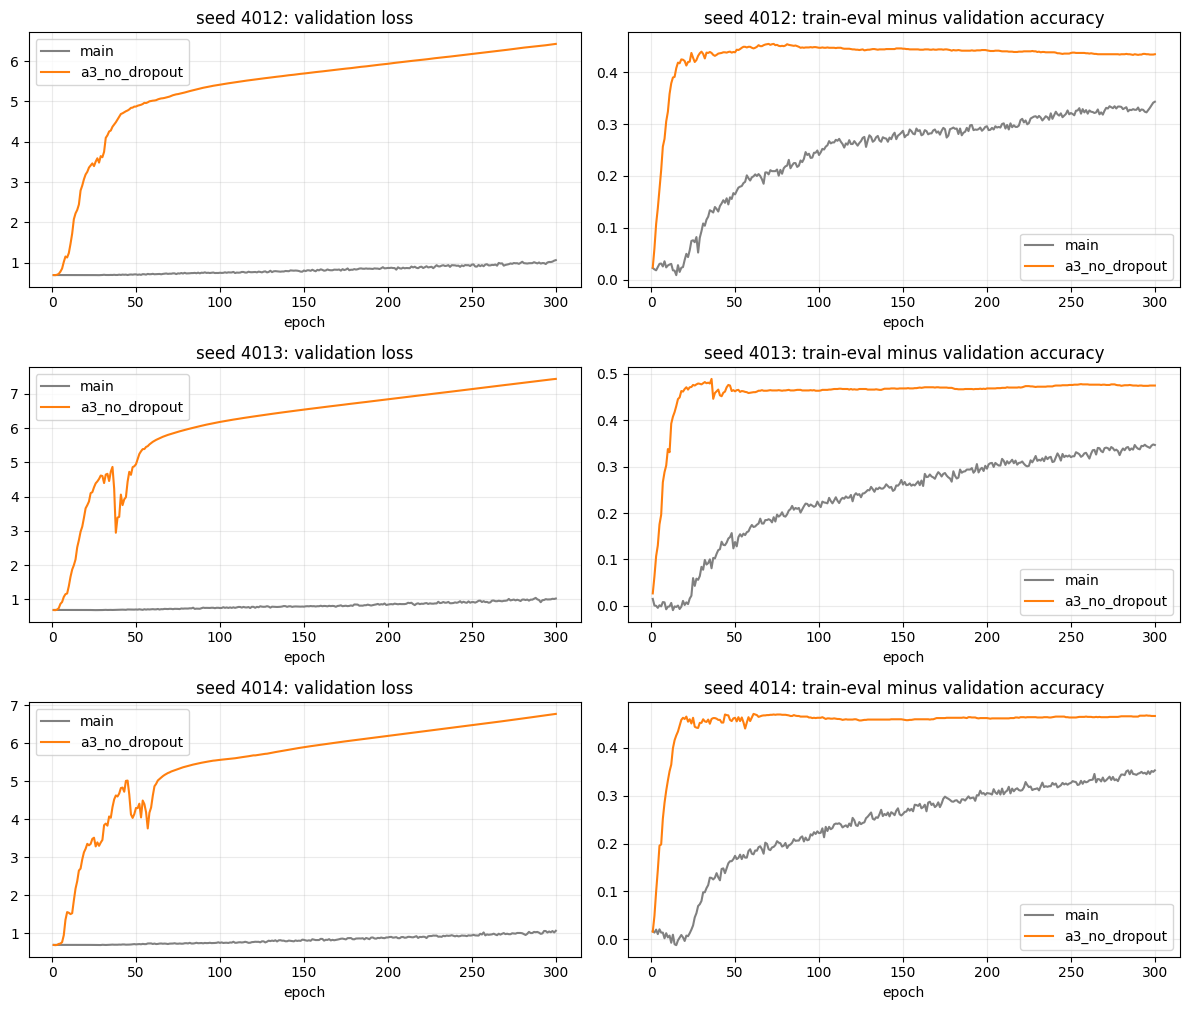

In [52]:
fig, axes = plt.subplots(len(SEEDS), 2, figsize=(12, 3.4 * len(SEEDS)))
for row, seed in enumerate(SEEDS):
    for label, folder, colour in [('main', E2_DIR, 'grey'), ('a3_no_dropout', E4_DIR / 'a3_no_dropout', 'tab:orange')]:
        h = pd.read_csv(folder / f'm3_transformer_lr{LR:g}_seed{seed}_history.csv')
        axes[row, 0].plot(h['epoch'], h['valid_loss'], color=colour, label=label)
        axes[row, 1].plot(h['epoch'], h['train_eval_accuracy'] - h['valid_accuracy'], color=colour, label=label)
    axes[row, 0].set_title(f'seed {seed}: validation loss')
    axes[row, 1].set_title(f'seed {seed}: train-eval minus validation accuracy')
    for ax in axes[row]:
        ax.set_xlabel('epoch'); ax.grid(alpha=0.25); ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / 'a3_gap_loss.png', dpi=150, bbox_inches='tight')
plt.show()

In [53]:
import platform
try:
    import torch
    torch_version, cuda_version = torch.__version__, torch.version.cuda
    device = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'
except ImportError:
    torch_version = cuda_version = device = 'not installed'
env = {'mode': 'training' if RUN_TRAINING else 'read saved logs',
       'python': platform.python_version(), 'torch': torch_version, 'cuda': cuda_version, 'device': device,
       'seeds': SEEDS, 'valid_rows': EXPECTED_VALID_ROWS,
       'repo_commit': E4_COMMIT, 'e2_commit': E2_COMMIT}
if RUN_TRAINING:
    # Training only: record the Colab environment of the new runs.
    freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
    (OUT_DIR / 'env_freeze.txt').write_text(freeze, encoding='utf-8')
    (OUT_DIR / 'env.json').write_text(json.dumps(env, indent=2), encoding='utf-8')
    print(env)
else:
    # Read mode: the environment record of the original runs (experiments/E4/env (1).json) is kept as it is.
    # This line shows the machine that is running the notebook now, for reference only.
    print('Environment of the original runs: experiments/E4/env (1).json (not overwritten in read mode).')
    print('This machine:', env)


Environment of the original runs: experiments/E4/env (1).json (not overwritten in read mode).
This machine: {'mode': 'read saved logs', 'python': '3.13.15', 'torch': '2.11.0+cu130', 'cuda': '13.0', 'device': 'Tesla T4', 'seeds': [4012, 4013, 4014], 'valid_rows': 1606, 'repo_commit': 'b102ef9d871b891d3a725ad3122703e8146166d4', 'e2_commit': 'd0268525b83d7af9f5d5b3a684b6ad8dec00d4d7'}


### 2.4.7 · Training summary (validation split)

One row per run, from the saved summaries and histories. Gaps are train-eval minus validation accuracy. Written to `training_summary.csv`. The paired comparison (Table 2) is in Section 3.

In [54]:
rows = []
for name in ['main'] + RUN_NAMES:
    folder = E2_DIR if name == 'main' else E4_DIR / name
    s = pd.read_csv(folder / 'm3_summary.csv')
    ends = [final_epoch(folder, int(seed)) for seed in SEEDS]
    rows.append({'run': name,
                 'valid_acc_mean': s['valid_accuracy'].mean(), 'valid_acc_sd': s['valid_accuracy'].std(),
                 'best_epoch_mean': s['best_epoch'].mean(), 'gap_at_best_mean': s['gap_at_best'].mean(),
                 'gap_at_end_mean': np.mean([e['gap_at_end'] for e in ends]),
                 'valid_loss_at_end_mean': np.mean([e['valid_loss_at_end'] for e in ends])})
training_summary = pd.DataFrame(rows).round(4)
training_summary.to_csv(OUT_DIR / 'training_summary.csv', index=False)
training_summary

,run,valid_acc_mean,valid_acc_sd,best_epoch_mean,gap_at_best_mean,gap_at_end_mean,valid_loss_at_end_mean
0,main,0.5940,0.0081,185.3333,0.2748,0.3474,1.0513
1,a1_no_position,0.5969,0.0050,183.3333,0.2644,0.3447,0.9469
2,a1_one_head,0.5863,0.0016,186.6667,0.2217,0.2798,0.9151
3,a3_no_dropout,0.5627,0.0121,10.6667,0.2549,0.4585,6.8791


**Figure 2 (comparison).** Validation accuracy of the main model and each ablation: mean over three seeds, with the sample standard deviation. The dashed line is chance (0.5; the two answer classes are balanced). Built from `training_summary`, the table written above.

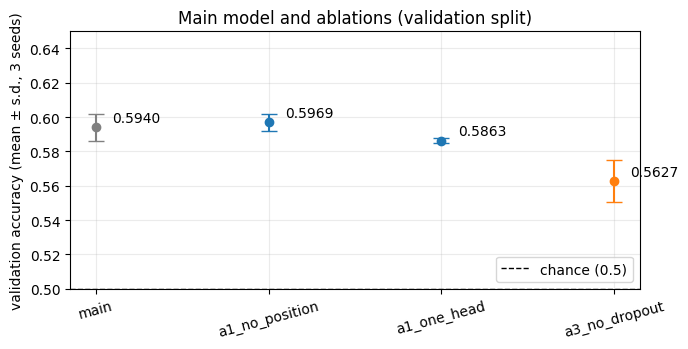

In [55]:
fig, ax = plt.subplots(figsize=(7, 3.6))
colours = {'main': 'grey', 'a1_no_position': 'tab:blue', 'a1_one_head': 'tab:blue', 'a3_no_dropout': 'tab:orange'}
for x, row in enumerate(training_summary.itertuples()):
    ax.errorbar(x, row.valid_acc_mean, yerr=row.valid_acc_sd, fmt='o', capsize=6, color=colours.get(row.run, 'tab:blue'))
    ax.annotate(f'{row.valid_acc_mean:.4f}', (x, row.valid_acc_mean), textcoords='offset points', xytext=(12, 4))
ax.axhline(0.5, ls='--', color='black', lw=1, label='chance (0.5)')
ax.set_xticks(range(len(training_summary)), training_summary['run'], rotation=15)
ax.set_ylabel('validation accuracy (mean ± s.d., 3 seeds)')
ax.set_ylim(0.5, 0.65)
ax.set_title('Main model and ablations (validation split)')
ax.legend(loc='lower right'); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT_DIR / 'valid_accuracy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# 3.Testing and Evaluation
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

This section reports the frozen test-set results, the baselines, the validation ablations, and the attention analysis. The test set has 1,838 questions. The validation set has 1,606 questions. Seeds are 4012, 4013, and 4014. A mean over seeds is accompanied by the sample standard deviation.

The main model, the B1 LSTM, and the B0 rules are scored again in this notebook on CPU and checked against the saved files. B2, B3, and the E4 training runs are read from the result files already in the repository. Each subsection names the script and the log that produced those files.

The next cell runs this section on its own, so it can run without the group's sections 0 and 1. It is kept in the group notebook: the timing at the end of section 3 uses the variable it sets, and it reloads the committed tokenizer that the E2 checkpoints were trained with.


In [56]:

# Standalone setup. Sections 0 and 1 of the group notebook already define
# DEVICE, BASE_PATH, and tokenizer. Section 1 loads ./tokenizer/piqa_bpe_v3.model
# after training it. This cell loads the committed model so the file can run alone.
import os
import sys
import time
import warnings
from pathlib import Path

import sentencepiece as spm
import torch

_root = Path.cwd().resolve()
for _candidate in [_root, *_root.parents]:
    if (_candidate / "scripts").is_dir() and (_candidate / "datasets" / "PIQA").is_dir():
        os.chdir(_candidate)
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break
else:
    raise FileNotFoundError("repository root (scripts/ and datasets/PIQA/) not found")

warnings.filterwarnings(
    "ignore",
    message="you are shuffling a 'StringArray' object",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="enable_nested_tensor is True",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="The PyTorch API of nested tensors is in prototype stage",
    category=UserWarning,
)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

BASE_PATH = Path("./datasets/PIQA")
tokenizer = spm.SentencePieceProcessor(model_file="scripts/tokenizer/piqa_bpe_v3.model")
_SECTION_STARTED = time.perf_counter()

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("vocab size:", tokenizer.get_piece_size())


Device: cuda
PyTorch: 2.11.0+cu130
vocab size: 8000


## 3.1 E2 result: final model configuration

The main model is the Transformer frozen at the end of E2. E2 chose it on the validation set. The dictionary in the next cell is that configuration: AdamW, learning rate 9e-4, dropout 0.3, batch size 512, 300 epochs, and no early stopping. The cell checks every entry against the matching field of `experiments/E2/results/final_3seed/config.json`. `model` is the single entry of `models`, and `learning_rate` is the single entry of `learning_rates`.

`momentum` is present in the config file because the same file shape is used for SGD. AdamW does not read it, so it is left out of the dictionary. The training entry point is `scripts.training.run_m3` with this config. The E2 notebook is `experiments/E2/E2 tuning updated.ipynb`. Checkpoints are `experiments/E2/checkpoints/`.


In [57]:
import json

import pandas as pd
from IPython.display import display

FINAL_MODEL = {
    "model": "transformer",
    "tokenizer": "scripts/tokenizer/piqa_bpe_v3.model",
    "optimizer": "adamw",
    "learning_rate": 0.0009,
    "weight_decay": 0.01,
    "batch_size": 512,
    "max_epochs": 300,
    "patience": None,
    "embedding_dim": 100,
    "hidden_size": 100,
    "num_heads": 4,
    "num_layers": 2,
    "dropout_rate": 0.3,
    "pooling": "cls",
    "enable_pos_emb": True,
    "seeds": [4012, 4013, 4014],
}

with open("experiments/E2/results/final_3seed/config.json", encoding="utf-8") as handle:
    e2_cfg = json.load(handle)

assert e2_cfg["models"] == [FINAL_MODEL["model"]]
assert e2_cfg["learning_rates"] == [FINAL_MODEL["learning_rate"]]
assert e2_cfg["seeds"] == FINAL_MODEL["seeds"]
for key in (
    "tokenizer",
    "optimizer",
    "weight_decay",
    "batch_size",
    "max_epochs",
    "patience",
    "embedding_dim",
    "hidden_size",
    "num_heads",
    "num_layers",
    "dropout_rate",
    "pooling",
    "enable_pos_emb",
):
    assert e2_cfg[key] == FINAL_MODEL[key], key


def _show_value(value):
    if value is None:
        return "null"
    if isinstance(value, bool):
        return "true" if value else "false"
    if isinstance(value, float):
        return format(value, "g")
    if isinstance(value, list):
        return ", ".join(_show_value(item) for item in value)
    return str(value)


config_table = pd.DataFrame(
    {"setting": list(FINAL_MODEL), "value": [_show_value(v) for v in FINAL_MODEL.values()]}
)
display(config_table)
print(f"Recorded in experiments/E2/results/final_3seed/config.json: _from = {e2_cfg['_from']}, _commit = {e2_cfg['_commit']}")


,setting,value
0,model,transformer
1,tokenizer,scripts/tokenizer/piqa_bpe_v3.model
2,optimizer,adamw
3,learning_rate,0.0009
4,weight_decay,0.01
5,batch_size,512
6,max_epochs,300
7,patience,null
8,embedding_dim,100
9,hidden_size,100


Recorded in experiments/E2/results/final_3seed/config.json: _from = s3_layers2, _commit = d0268525b83d7af9f5d5b3a684b6ad8dec00d4d7


## 3.2 E2 result: main model on the test set

This cell loads the three E2 checkpoints `experiments/E2/checkpoints/m3_transformer_lr0.0009_seed{4012,4013,4014}_best.pt`, builds each network with `scripts.training.run_m3.build_model` from the E2 config, and scores the test set with `scripts.evaluation.evaluate.evaluate`. The loader uses `shuffle=False` and the training batch size, 512, so the padding matches the saved run.

The saved test files were written by `scripts.evaluation.evaluate_checkpoint` into `reports/test/main/seed*/`. The cell checks that `row_id`, `label`, `pred`, and `correct` match those files on every question. Logits and `prob_sol2` are compared with a maximum absolute gap below 1e-4, because the saved CSV does not keep a bit-exact float. The comparison is the three seeds against each other: the same architecture, the same hyperparameters, and a different initialisation seed.


In [58]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

from scripts.data_loader.piqa_dataloader import PIQACollator, tokenize_piqa_dataframe
from scripts.evaluation.evaluate import evaluate
from scripts.training.run_m3 import build_model, make_loader

warnings.filterwarnings(
    "ignore",
    message="you are shuffling a 'StringArray' object",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="enable_nested_tensor is True",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="The PyTorch API of nested tensors is in prototype stage",
    category=UserWarning,
)

SEEDS = list(FINAL_MODEL["seeds"])
METRIC_KEYS = ("accuracy", "precision", "recall", "f1")


def load_json(path):
    with open(path, encoding="utf-8") as handle:
        return json.load(handle)


def mean_std(values):
    arr = np.asarray(list(values), dtype=float)
    mean = float(arr.mean())
    if len(arr) < 2:
        return mean, float("nan")
    return mean, float(arr.std(ddof=1))


def fmt_pct(mean, std=None):
    if std is None or std != std:
        return f"{100 * mean:.1f}"
    return f"{100 * mean:.1f} ± {100 * std:.1f}"


def fmt_prop(mean, std=None, digits=4):
    if std is None or std != std:
        return f"{mean:.{digits}f}"
    return f"{mean:.{digits}f} ± {std:.{digits}f}"


def check_predictions(live, path, atol=1e-4):
    saved = pd.read_csv(path)
    merged = live.merge(saved, on="row_id", suffixes=("_live", "_saved"))
    if len(merged) != len(live) or len(merged) != len(saved):
        raise AssertionError(f"row_id mismatch: {path}")
    for column in ("label", "pred"):
        live_values = merged[f"{column}_live"].to_numpy()
        saved_values = merged[f"{column}_saved"].to_numpy()
        if not np.array_equal(live_values, saved_values):
            raise AssertionError(f"{column} mismatch: {path}")
    saved_correct = merged["correct_saved"]
    if saved_correct.dtype != bool:
        saved_correct = saved_correct.astype(str).str.lower().isin(["true", "1"])
    live_correct = merged["correct_live"].astype(bool).to_numpy()
    if not np.array_equal(live_correct, np.asarray(saved_correct, dtype=bool)):
        raise AssertionError(f"correct mismatch: {path}")
    gaps = []
    for column in ("logit_1", "logit_2", "prob_sol2"):
        gap = float(np.max(np.abs(
            merged[f"{column}_live"].to_numpy() - merged[f"{column}_saved"].to_numpy()
        )))
        if gap >= atol:
            raise AssertionError(f"{column} gap {gap} in {path}")
        gaps.append(gap)
    return max(gaps)


def eval_checkpoint(model_name, cfg, checkpoint):
    model = build_model(
        model_name, tokenizer.get_piece_size(), tokenizer.pad_id(), cfg,
    ).to(DEVICE)
    state = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
    model.load_state_dict(state)
    n_params = int(sum(parameter.numel() for parameter in model.parameters()))
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="The PyTorch API of nested tensors is in prototype stage",
            category=UserWarning,
        )
        metrics, predictions = evaluate(model, TEST_LOADER, DEVICE)
    del model
    return metrics, predictions, n_params


_train_df, _valid_df, test_df = tokenize_piqa_dataframe(BASE_PATH, tokenizer)
test_df = test_df.reset_index(drop=True)
TEST_N = len(test_df)
TEST_LOADER = make_loader(
    test_df,
    PIQACollator(tokenizer),
    batch_size=int(FINAL_MODEL["batch_size"]),
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
    shuffle=False,
)

MAIN_TEST = []
MAIN_OUTCOME = {}
for seed in SEEDS:
    checkpoint = (
        Path("experiments/E2/checkpoints")
        / f"m3_transformer_lr{FINAL_MODEL['learning_rate']:g}_seed{seed}_best.pt"
    )
    saved_metrics = load_json(f"reports/test/main/seed{seed}/metrics.json")
    metrics, predictions, n_params = eval_checkpoint("transformer", e2_cfg, checkpoint)
    gap = check_predictions(predictions, f"reports/test/main/seed{seed}/test_predictions.csv")
    for key in METRIC_KEYS:
        if abs(metrics[key] - saved_metrics["metrics"][key]) > 1e-9:
            raise AssertionError(f"seed {seed} {key} disagrees with metrics.json")
    if n_params != saved_metrics["n_params"]:
        raise AssertionError(f"parameter count {n_params} != {saved_metrics['n_params']}")
    MAIN_TEST.append({"seed": seed, "gap": gap, **{key: metrics[key] for key in METRIC_KEYS}})
    MAIN_OUTCOME[seed] = (
        predictions["label"].to_numpy(),
        predictions["correct"].astype(bool).to_numpy(),
    )

MAIN_N_PARAMS = n_params
if TEST_N != 1838:
    raise AssertionError(f"test set size is {TEST_N}")

per_seed = pd.DataFrame(MAIN_TEST)
shown = per_seed.copy()
for key in METRIC_KEYS:
    shown[key] = shown[key].map(lambda value: f"{value:.4f}")
shown["score gap"] = shown["gap"].map(lambda value: f"{value:.2e}")
display(shown[["seed", "accuracy", "precision", "recall", "f1", "score gap"]])

summary_rows = []
for key in METRIC_KEYS:
    mean, std = mean_std(per_seed[key])
    summary_rows.append({
        "metric": "macro-F1" if key == "f1" else key,
        "mean ± sd": fmt_prop(mean, std),
        "percent": fmt_pct(mean, std),
    })
display(pd.DataFrame(summary_rows))
MAIN_ACC_TEXT = fmt_pct(*mean_std(per_seed["accuracy"]))
print(f"Parameters: {MAIN_N_PARAMS:,}")
print(f"Test accuracy: {MAIN_ACC_TEXT}")
if MAIN_ACC_TEXT != "58.9 ± 0.2":
    raise AssertionError(f"main test accuracy formatted as {MAIN_ACC_TEXT!r}")


,seed,accuracy,precision,recall,f1,score gap
0,4012,0.5914,0.5915,0.5915,0.5914,1.46e-06
1,4013,0.5892,0.5894,0.5894,0.5892,1.42e-06
2,4014,0.5871,0.5872,0.5871,0.5870,1.66e-06


,metric,mean ± sd,percent
0,accuracy,0.5892 ± 0.0022,58.9 ± 0.2
1,precision,0.5894 ± 0.0022,58.9 ± 0.2
2,recall,0.5893 ± 0.0022,58.9 ± 0.2
3,macro-F1,0.5892 ± 0.0022,58.9 ± 0.2


Parameters: 933,357
Test accuracy: 58.9 ± 0.2


## 3.3 E3 baseline B1 (LSTM, no attention) on the test set

B1 is a bidirectional LSTM with attention turned off. `RNNWithAttention` then uses the last hidden state. The training config is `config/b1_lstm_noattn.json`: the E2 protocol, with LSTM in place of the Transformer. AdamW, weight decay 0.01, learning rate 9e-4, dropout 0.3, batch size 512, 300 epochs, no early stopping, seeds 4012, 4013, and 4014. Training was `scripts.training.run_m3`. The Colab log is `reports/baselines/lstm_noattn.ipynb`. Checkpoints are `reports/baselines/b1_lstm_noattn/m3_lstm_lr0.0009_seed*_best.pt`.

The cell scores those checkpoints on the same test loader as section 3.2 and checks them against `reports/test/b1/seed*/`, which `scripts.evaluation.evaluate_checkpoint` wrote. The comparison is B1 against the main Transformer: same data, same optimiser schedule, and no attention in B1.


In [59]:
from pathlib import Path

import pandas as pd
from IPython.display import display

with open("config/b1_lstm_noattn.json", encoding="utf-8") as handle:
    b1_cfg = json.load(handle)

if int(b1_cfg["batch_size"]) != int(FINAL_MODEL["batch_size"]):
    raise RuntimeError("B1 batch size differs from the test loader built in section 3.2")

b1_lr = b1_cfg["learning_rates"][0]
b1_name = b1_cfg["models"][0]
B1_TEST = []
B1_OUTCOME = {}
for seed in SEEDS:
    checkpoint = (
        Path("reports/baselines/b1_lstm_noattn")
        / f"m3_{b1_name}_lr{b1_lr:g}_seed{seed}_best.pt"
    )
    saved_metrics = load_json(f"reports/test/b1/seed{seed}/metrics.json")
    metrics, predictions, n_params = eval_checkpoint(b1_name, b1_cfg, checkpoint)
    gap = check_predictions(predictions, f"reports/test/b1/seed{seed}/test_predictions.csv")
    for key in METRIC_KEYS:
        if abs(metrics[key] - saved_metrics["metrics"][key]) > 1e-9:
            raise AssertionError(f"B1 seed {seed} {key} disagrees with metrics.json")
    if n_params != saved_metrics["n_params"]:
        raise AssertionError(f"B1 parameter count {n_params} != {saved_metrics['n_params']}")
    B1_TEST.append({"seed": seed, "gap": gap, **{key: metrics[key] for key in METRIC_KEYS}})
    B1_OUTCOME[seed] = (
        predictions["label"].to_numpy(),
        predictions["correct"].astype(bool).to_numpy(),
    )

B1_N_PARAMS = n_params
b1_seed_table = pd.DataFrame(B1_TEST)
b1_shown = b1_seed_table.copy()
for key in METRIC_KEYS:
    b1_shown[key] = b1_shown[key].map(lambda value: f"{value:.4f}")
b1_shown["score gap"] = b1_shown["gap"].map(lambda value: f"{value:.2e}")
display(b1_shown[["seed", "accuracy", "precision", "recall", "f1", "score gap"]])

b1_summary = []
for key in METRIC_KEYS:
    mean, std = mean_std(b1_seed_table[key])
    b1_summary.append({
        "metric": "macro-F1" if key == "f1" else key,
        "mean ± sd": fmt_prop(mean, std),
        "percent": fmt_pct(mean, std),
    })
display(pd.DataFrame(b1_summary))
B1_ACC_TEXT = fmt_pct(*mean_std(b1_seed_table["accuracy"]))
print(f"Parameters: {B1_N_PARAMS:,}")
print(f"Test accuracy: {B1_ACC_TEXT}")
if B1_ACC_TEXT != "58.3 ± 0.5":
    raise AssertionError(f"B1 test accuracy formatted as {B1_ACC_TEXT!r}")


,seed,accuracy,precision,recall,f1,score gap
0,4012,0.5789,0.5788,0.5788,0.5788,4.38e-06
1,4013,0.5881,0.5881,0.5880,0.5880,4.02e-06
2,4014,0.5832,0.5832,0.5833,0.5832,5.68e-06


,metric,mean ± sd,percent
0,accuracy,0.5834 ± 0.0046,58.3 ± 0.5
1,precision,0.5834 ± 0.0046,58.3 ± 0.5
2,recall,0.5834 ± 0.0046,58.3 ± 0.5
3,macro-F1,0.5833 ± 0.0046,58.3 ± 0.5


Parameters: 1,082,401
Test accuracy: 58.3 ± 0.5


## 3.4 E3 baselines B0, B2, B3 on the test set

B1 is the trained LSTM in section 3.3. This section covers the rule baseline and the pretrained models.

**B0** (`scripts.baselines.b0_trivial`). Three fixed rules, scored on the validation set and the test set. Nothing is chosen from the validation scores. `random` draws once from a NumPy Generator seeded 4012, validation first and then test. `always_sol1` always picks solution 1. `shorter` picks the solution with fewer characters and picks solution 1 when the lengths are equal. The reported B0 number is `shorter`. The cell calls `run(output_dir=...)` with a temporary directory and checks the accuracies against `reports/baselines/b0_trivial/metrics.json`. The saved directory is left unchanged.

**B2** (`scripts.baselines.b2_zero_shot_lm`). Zero-shot causal language models, `openai-community/gpt2` and `Qwen/Qwen2.5-0.5B` (the base model). Each model's own tokenizer is used. The prompt is `Question: {goal}\nAnswer:` and the continuation is a space plus the solution. The score of a solution is the log-probability of its continuation tokens, either the sum or the mean over tokens. The score with the higher validation accuracy is kept. A tie would keep the mean. Both models kept the mean. Scoring is float32. These runs are read from `reports/baselines/b2_zero_shot_lm/`. The Colab log is `reports/baselines/colab_b2_b3.ipynb`.

**B3** (`scripts.baselines.b3_finetune`). `AutoModelForMultipleChoice` on `distilbert-base-uncased` and `roberta-base`, each with its own tokenizer. A question is two pairs, `(goal, sol1)` and `(goal, sol2)`, truncated at 128 tokens and padded inside the batch, shape `[B, 2, L]`. The optimiser is AdamW with weight decay 0.01, a 10% warmup, then linear decay to 0, batch size 16, and gradient clipping at 1.0. The best epoch is the one with the highest validation accuracy. Those weights stay in memory and the test set is scored once. Seeds are 4012, 4013, and 4014.

DistilBERT was trained for 3 epochs at learning rate 2e-5. Its files are `reports/baselines/b3_finetune/distilbert-base-uncased/`. The same Colab log as B2 records that run.

RoBERTa was first trained with that same schedule, 3 epochs at learning rate 2e-5. The training loss stayed near ln 2, about 0.693, which is the cross-entropy of a uniform guess over two answers, so the model did not learn. That run is kept in `reports/baselines/b3_finetune/roberta-base/`. It was then trained again for 10 epochs at learning rate 1e-5, with the same batch size, maximum length, and warmup. The report uses this second run, `reports/baselines/b3_roberta_10ep/roberta-base/`. The log is `reports/baselines/b3_roberta_10ep/roberta.ipynb`.


In [60]:
import contextlib
import io
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import display

from scripts.baselines.b0_trivial import run as run_b0

repo_root = Path.cwd().resolve()
with tempfile.TemporaryDirectory() as tmp:
    tmp_path = Path(tmp).resolve()
    if repo_root == tmp_path or repo_root in tmp_path.parents:
        raise RuntimeError(f"temporary directory {tmp_path} is inside the repository")
    with contextlib.redirect_stdout(io.StringIO()):
        live_b0 = run_b0(output_dir=tmp_path)
    B0_SHORTER = pd.read_csv(tmp_path / "shorter_test_predictions.csv")

saved_b0 = load_json("reports/baselines/b0_trivial/metrics.json")
b0_rows = []
for rule in ("random", "always_sol1", "shorter"):
    for split in ("valid", "test"):
        live_acc = live_b0["rules"][rule][split]["accuracy"]
        saved_acc = saved_b0["rules"][rule][split]["accuracy"]
        if abs(live_acc - saved_acc) > 1e-12:
            raise AssertionError(f"B0 {rule} {split}: live {live_acc} saved {saved_acc}")
    b0_rows.append({
        "rule": rule,
        "valid accuracy": saved_b0["rules"][rule]["valid"]["accuracy"],
        "test accuracy": saved_b0["rules"][rule]["test"]["accuracy"],
        "test macro-F1": saved_b0["rules"][rule]["test"]["f1"],
        "matches saved": True,
    })
display(pd.DataFrame(b0_rows))
B0_ACC_TEXT = fmt_pct(saved_b0["rules"]["shorter"]["test"]["accuracy"])
print(f"B0 shorter test accuracy: {B0_ACC_TEXT}")
if B0_ACC_TEXT != "53.2":
    raise AssertionError(f"B0 shorter formatted as {B0_ACC_TEXT!r}")

def b2_row(folder, label):
    payload = load_json(Path("reports/baselines/b2_zero_shot_lm") / folder / "metrics.json")
    selection = payload["selection"]
    return {
        "model": label,
        "parameters": f"{payload['n_params']:,}",
        "chosen score": selection["chosen_score"],
        "valid sum": selection["valid_sum_accuracy"],
        "valid mean": selection["valid_mean_accuracy"],
        "test accuracy": payload["test"]["accuracy"],
        "test macro-F1": payload["test"]["f1"],
    }, payload

b2_table = []
gpt2_row, gpt2_metrics = b2_row("gpt2", "GPT-2")
qwen_row, qwen_metrics = b2_row("qwen2.5-0.5b", "Qwen2.5-0.5B")
b2_table.extend([gpt2_row, qwen_row])
display(pd.DataFrame(b2_table))
if gpt2_metrics["selection"]["chosen_score"] != "mean" or qwen_metrics["selection"]["chosen_score"] != "mean":
    raise AssertionError("B2 selection on the validation set was expected to be mean for both models")
GPT2_ACC_TEXT = fmt_pct(gpt2_metrics["test"]["accuracy"])
QWEN_ACC_TEXT = fmt_pct(qwen_metrics["test"]["accuracy"])
print(f"GPT-2 test accuracy: {GPT2_ACC_TEXT}")
print(f"Qwen2.5-0.5B test accuracy: {QWEN_ACC_TEXT}")
if GPT2_ACC_TEXT != "61.5" or QWEN_ACC_TEXT != "69.5":
    raise AssertionError(f"B2 formatted as {GPT2_ACC_TEXT!r} and {QWEN_ACC_TEXT!r}")

def b3_seed_f1(directory):
    values = []
    for seed in SEEDS:
        payload = load_json(Path(directory) / f"seed{seed}" / "metrics.json")
        values.append(payload["test"]["f1"])
    return values

def b3_summary_row(directory, label):
    summary = load_json(Path(directory) / "summary.json")
    f1_values = b3_seed_f1(directory)
    n_params = load_json(Path(directory) / "seed4012" / "metrics.json")["n_params"]
    return {
        "model": label,
        "parameters": f"{n_params:,}",
        "epochs / lr": summary.get("epochs_lr", ""),
        "valid accuracy": fmt_pct(summary["valid_accuracy_mean"], summary["valid_accuracy_std"]),
        "test accuracy": fmt_pct(summary["test_accuracy_mean"], summary["test_accuracy_std"]),
        "test macro-F1": fmt_pct(*mean_std(f1_values)),
    }, summary, n_params

distil_dir = "reports/baselines/b3_finetune/distilbert-base-uncased"
roberta_failed_dir = "reports/baselines/b3_finetune/roberta-base"
roberta_dir = "reports/baselines/b3_roberta_10ep/roberta-base"
distil_row, distil_summary, DISTIL_N_PARAMS = b3_summary_row(distil_dir, "DistilBERT, 3 epochs, lr 2e-5")
failed_row, failed_summary, _failed_params = b3_summary_row(
    roberta_failed_dir, "RoBERTa, 3 epochs, lr 2e-5",
)
roberta_row, roberta_summary, ROBERTA_N_PARAMS = b3_summary_row(
    roberta_dir, "RoBERTa, 10 epochs, lr 1e-5",
)
for row, note in (
    (distil_row, "3 epochs, lr 2e-5"),
    (failed_row, "3 epochs, lr 2e-5"),
    (roberta_row, "10 epochs, lr 1e-5"),
):
    row["epochs / lr"] = note
display(pd.DataFrame([distil_row, failed_row, roberta_row]))

DISTIL_ACC_TEXT = fmt_pct(distil_summary["test_accuracy_mean"], distil_summary["test_accuracy_std"])
ROBERTA_ACC_TEXT = fmt_pct(roberta_summary["test_accuracy_mean"], roberta_summary["test_accuracy_std"])
DISTIL_F1_TEXT = distil_row["test macro-F1"]
ROBERTA_F1_TEXT = roberta_row["test macro-F1"]
print(f"DistilBERT test accuracy: {DISTIL_ACC_TEXT}")
print(f"RoBERTa 10-epoch test accuracy: {ROBERTA_ACC_TEXT}")
if DISTIL_ACC_TEXT != "62.2 ± 0.8" or ROBERTA_ACC_TEXT != "70.5 ± 0.5":
    raise AssertionError(f"B3 formatted as {DISTIL_ACC_TEXT!r} and {ROBERTA_ACC_TEXT!r}")


,rule,valid accuracy,test accuracy,test macro-F1,matches saved
0,random,0.501245,0.479325,0.479318,True
1,always_sol1,0.504981,0.495103,0.331150,True
2,shorter,0.530511,0.531556,0.530599,True


B0 shorter test accuracy: 53.2


,model,parameters,chosen score,valid sum,valid mean,test accuracy,test macro-F1
0,GPT-2,"124,439,808",mean,0.626401,0.640722,0.614799,0.614415
1,Qwen2.5-0.5B,"494,032,768",mean,0.701121,0.719801,0.695321,0.695321


GPT-2 test accuracy: 61.5
Qwen2.5-0.5B test accuracy: 69.5


,model,parameters,epochs / lr,valid accuracy,test accuracy,test macro-F1
0,"DistilBERT, 3 epochs, lr 2e-5","66,954,241","3 epochs, lr 2e-5",61.7 ± 0.2,62.2 ± 0.8,62.2 ± 0.8
1,"RoBERTa, 3 epochs, lr 2e-5","124,646,401","3 epochs, lr 2e-5",57.9 ± 5.9,56.6 ± 4.7,56.6 ± 4.7
2,"RoBERTa, 10 epochs, lr 1e-5","124,646,401","10 epochs, lr 1e-5",70.9 ± 0.8,70.5 ± 0.5,70.5 ± 0.5


DistilBERT test accuracy: 62.2 ± 0.8
RoBERTa 10-epoch test accuracy: 70.5 ± 0.5


## 3.5 Main results table (Table 1, test set)

One table for every model scored on the 1,838 test questions. Accuracy and macro-F1 for a three-seed model are the mean and the sample standard deviation. B0, GPT-2, and Qwen2.5-0.5B are single runs, so they have a point value.

McNemar uses `scripts.evaluation.evaluate.mcnemar_test`: a continuity correction `(|b − c| − 1)² / (b + c)`, with the p-value from the complementary error function. The main model is the reference. For B1, DistilBERT, and the 10-epoch RoBERTa run, seed 4012 is paired with seed 4012, and the same for 4013 and 4014. B0, GPT-2, and Qwen each have one prediction file, and that file is paired with each of the three main seeds. The table reports the minimum and the maximum of those three p-values. The first RoBERTa run is omitted here; section 3.4 records it.


In [61]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from scripts.evaluation.evaluate import mcnemar_test


def load_outcome(path):
    frame = pd.read_csv(path)
    labels = frame["label"].to_numpy()
    correct = frame["correct"]
    if correct.dtype != bool:
        correct = correct.astype(str).str.lower().isin(["true", "1"])
    return labels, np.asarray(correct, dtype=bool)


def p_same_seed(outcomes):
    p_values = []
    for seed in SEEDS:
        labels, correct = outcomes[seed]
        main_labels, main_correct = MAIN_OUTCOME[seed]
        if not np.array_equal(main_labels, labels):
            raise AssertionError(f"labels differ from the main model at seed {seed}")
        p_values.append(mcnemar_test(main_correct, correct)["p_value"])
    return p_values


def p_against_each_main_seed(labels, correct):
    p_values = []
    for seed in SEEDS:
        main_labels, main_correct = MAIN_OUTCOME[seed]
        if not np.array_equal(main_labels, labels):
            raise AssertionError(f"labels differ from the main model at seed {seed}")
        p_values.append(mcnemar_test(main_correct, correct)["p_value"])
    return p_values


def fmt_p_range(p_values):
    def one(p_value):
        if p_value < 0.001:
            return f"{p_value:.2e}"
        return f"{p_value:.3f}"

    low, high = one(min(p_values)), one(max(p_values))
    if low == high:
        return low
    return f"{low}–{high}"


b1_p = p_same_seed(B1_OUTCOME)
distil_outcomes = {
    seed: load_outcome(
        f"reports/baselines/b3_finetune/distilbert-base-uncased/seed{seed}/test_predictions.csv"
    )
    for seed in SEEDS
}
roberta_outcomes = {
    seed: load_outcome(
        f"reports/baselines/b3_roberta_10ep/roberta-base/seed{seed}/test_predictions.csv"
    )
    for seed in SEEDS
}
distil_p = p_same_seed(distil_outcomes)
roberta_p = p_same_seed(roberta_outcomes)

shorter_labels = B0_SHORTER["label"].to_numpy()
shorter_correct = B0_SHORTER["correct"]
if shorter_correct.dtype != bool:
    shorter_correct = shorter_correct.astype(str).str.lower().isin(["true", "1"])
b0_p = p_against_each_main_seed(shorter_labels, np.asarray(shorter_correct, dtype=bool))
gpt2_p = p_against_each_main_seed(
    *load_outcome("reports/baselines/b2_zero_shot_lm/gpt2/test_predictions.csv")
)
qwen_p = p_against_each_main_seed(
    *load_outcome("reports/baselines/b2_zero_shot_lm/qwen2.5-0.5b/test_predictions.csv")
)

result_table = pd.DataFrame([
    {
        "model": "Main Transformer",
        "parameters": f"{MAIN_N_PARAMS:,}",
        "test accuracy": MAIN_ACC_TEXT,
        "macro-F1": fmt_pct(*mean_std(item["f1"] for item in MAIN_TEST)),
        "McNemar p vs main": "—",
    },
    {
        "model": "B1 BiLSTM, no attention",
        "parameters": f"{B1_N_PARAMS:,}",
        "test accuracy": B1_ACC_TEXT,
        "macro-F1": fmt_pct(*mean_std(item["f1"] for item in B1_TEST)),
        "McNemar p vs main": fmt_p_range(b1_p),
    },
    {
        "model": "B0 shorter",
        "parameters": "0",
        "test accuracy": B0_ACC_TEXT,
        "macro-F1": fmt_pct(saved_b0["rules"]["shorter"]["test"]["f1"]),
        "McNemar p vs main": fmt_p_range(b0_p),
    },
    {
        "model": "GPT-2",
        "parameters": f"{gpt2_metrics['n_params']:,}",
        "test accuracy": GPT2_ACC_TEXT,
        "macro-F1": fmt_pct(gpt2_metrics["test"]["f1"]),
        "McNemar p vs main": fmt_p_range(gpt2_p),
    },
    {
        "model": "Qwen2.5-0.5B",
        "parameters": f"{qwen_metrics['n_params']:,}",
        "test accuracy": QWEN_ACC_TEXT,
        "macro-F1": fmt_pct(qwen_metrics["test"]["f1"]),
        "McNemar p vs main": fmt_p_range(qwen_p),
    },
    {
        "model": "DistilBERT",
        "parameters": f"{DISTIL_N_PARAMS:,}",
        "test accuracy": DISTIL_ACC_TEXT,
        "macro-F1": DISTIL_F1_TEXT,
        "McNemar p vs main": fmt_p_range(distil_p),
    },
    {
        "model": "RoBERTa-base",
        "parameters": f"{ROBERTA_N_PARAMS:,}",
        "test accuracy": ROBERTA_ACC_TEXT,
        "macro-F1": ROBERTA_F1_TEXT,
        "McNemar p vs main": fmt_p_range(roberta_p),
    },
])
display(result_table)

expected_accuracy = {
    "Main Transformer": "58.9 ± 0.2",
    "B1 BiLSTM, no attention": "58.3 ± 0.5",
    "B0 shorter": "53.2",
    "GPT-2": "61.5",
    "Qwen2.5-0.5B": "69.5",
    "DistilBERT": "62.2 ± 0.8",
    "RoBERTa-base": "70.5 ± 0.5",
}
for model_name, expected in expected_accuracy.items():
    actual = result_table.loc[result_table["model"] == model_name, "test accuracy"].item()
    if actual != expected:
        raise AssertionError(f"{model_name} test accuracy is {actual!r}, expected {expected!r}")


,model,parameters,test accuracy,macro-F1,McNemar p vs main
0,Main Transformer,"933,357",58.9 ± 0.2,58.9 ± 0.2,—
1,"B1 BiLSTM, no attention","1,082,401",58.3 ± 0.5,58.3 ± 0.5,0.389–0.968
2,B0 shorter,0,53.2,53.1,3.41e-04–8.35e-04
3,GPT-2,"124,439,808",61.5,61.4,0.092–0.154
4,Qwen2.5-0.5B,"494,032,768",69.5,69.5,3.58e-12–1.80e-11
5,DistilBERT,"66,954,241",62.2 ± 0.8,62.2 ± 0.8,0.009–0.079
6,RoBERTa-base,"124,646,401",70.5 ± 0.5,70.5 ± 0.5,2.11e-17–6.74e-14


## 3.6 E4 ablation results (Table 2, validation set)

E4 changes one thing at a time on the frozen E2 model and scores the validation set. The test set is untouched. The trained ablations are A1'-a (positional encoding off), A1'-b (one attention head), and A3 (dropout 0). A2-a keeps the E2 checkpoints and removes the goal at evaluation only, so the input is `[CLS] [SEP]` solution `[EOS]`. This round covers those four. The training and evaluation log is `experiments/E4/E4_ablation1 (2).ipynb`, with per-run files under `experiments/E4/e4_logs/`. The tables below are built from `experiments/E4/e4_table1.csv`, `experiments/E4/e4_table2.csv`, and `experiments/E4/e4_a2a_summary.csv`. Ablation weights are on Drive; A2-a uses the E2 checkpoints.

Δ is the ablation accuracy minus the main-model accuracy, in percentage points. McNemar is paired inside each seed on the 1,606 validation questions. The p-values are listed in seed order 4012 / 4013 / 4014.

A1'-a and A1'-b stay close to the main model: every seed has p above 0.05, and the one-head deltas change sign across seeds. A3 is lower on all three seeds. Its best epoch is about 11, and the validation loss at epoch 300 is about 6.88 against about 1.05 for the main model, so the accuracy gap mixes the dropout change with an early peak. A2-a is lower on all three seeds, by about 2.4 points. The model was trained with the goal present, so this measures sensitivity to that input.


In [62]:
import math

import pandas as pd
from IPython.display import display

table1 = pd.read_csv("experiments/E4/e4_table1.csv")
table2 = pd.read_csv("experiments/E4/e4_table2.csv")
a2a = pd.read_csv("experiments/E4/e4_a2a_summary.csv", index_col=0)
main_row = table1.loc[table1["experiment"] == "main (E2)"].iloc[0]


def fmt_p_seed(p_value):
    if p_value >= 0.1:
        return f"{p_value:.2f}"
    return f"{p_value:.3f}"


def fmt_pp(delta):
    pp = 100 * float(delta)
    if pp > 0:
        return f"+{pp:.2f}"
    if pp < 0:
        return f"−{abs(pp):.2f}"
    return "0.00"


def ablation_row(label, accuracy, std, delta, p_values):
    if p_values is None:
        p_text = "—"
        delta_text = "—"
    else:
        ordered = [float(p) for p in p_values]
        p_text = " / ".join(fmt_p_seed(p) for p in ordered)
        delta_text = fmt_pp(delta)
    return {
        "experiment": label,
        "valid accuracy": f"{float(accuracy):.4f} ± {float(std):.4f}",
        "Δ vs main (pp)": delta_text,
        "McNemar p (4012 / 4013 / 4014)": p_text,
    }


ablation_rows = [
    ablation_row("Main (E2)", main_row["valid_mean"], main_row["valid_sd"], None, None),
]
for key, label in (
    ("a1_no_position", "A1'-a no position"),
    ("a1_one_head", "A1'-b one head"),
    ("a3_no_dropout", "A3 no dropout"),
):
    row = table1.loc[table1["experiment"] == key].iloc[0]
    paired = table2.loc[table2["experiment"] == key].sort_values("seed")
    ablation_rows.append(ablation_row(
        label,
        row["valid_mean"],
        row["valid_sd"],
        float(row["valid_mean"]) - float(main_row["valid_mean"]),
        paired["p_value"],
    ))

a2_paired = table2.loc[table2["experiment"] == "a2a_no_goal"].sort_values("seed")
ablation_rows.append(ablation_row(
    "A2-a no goal (eval only)",
    a2a.loc["mean", "other_acc"],
    a2a.loc["std", "other_acc"],
    a2a.loc["mean", "delta"],
    a2_paired["p_value"],
))
ablation_table = pd.DataFrame(ablation_rows)
display(ablation_table)

expected_ablation = {
    "Main (E2)": ("0.5940 ± 0.0081", "—", "—"),
    "A1'-a no position": ("0.5969 ± 0.0050", "+0.29", "0.88 / 0.96 / 0.57"),
    "A1'-b one head": ("0.5863 ± 0.0016", "−0.77", "0.24 / 0.33 / 0.83"),
    "A3 no dropout": ("0.5627 ± 0.0121", "−3.13", "0.14 / 0.006 / 0.064"),
    "A2-a no goal (eval only)": ("0.5702 ± 0.0051", "−2.39", "0.033 / 0.003 / 0.099"),
}
for label, expected in expected_ablation.items():
    got = ablation_table.loc[ablation_table["experiment"] == label].iloc[0]
    actual = (got["valid accuracy"], got["Δ vs main (pp)"], got["McNemar p (4012 / 4013 / 4014)"])
    if actual != expected:
        raise AssertionError(f"{label}: {actual} != {expected}")

def fmt_gap(mean, std):
    def half_up(value):
        return math.floor(float(value) * 1000 + 0.5) / 1000
    return f"{half_up(mean):.3f} ± {half_up(std):.3f}"

gap_rows = []
for key, label in (("main (E2)", "Main"), ("a3_no_dropout", "A3 no dropout")):
    row = table1.loc[table1["experiment"] == key].iloc[0]
    gap_rows.append({
        "model": label,
        "gap at best epoch": fmt_gap(row["gap_at_best_mean"], row["gap_at_best_sd"]),
        "gap at epoch 300": fmt_gap(row["gap_at_end_mean"], row["gap_at_end_sd"]),
        "valid loss at epoch 300": f"{float(row['valid_loss_at_end_mean']):.2f}",
        "best epoch": str(int(round(float(row["best_epoch_mean"])))),
    })
gap_table = pd.DataFrame(gap_rows)
display(gap_table)
expected_gap = {
    "Main": ("0.275 ± 0.013", "0.347 ± 0.005", "1.05", "185"),
    "A3 no dropout": ("0.255 ± 0.187", "0.459 ± 0.021", "6.88", "11"),
}
for label, expected in expected_gap.items():
    got = gap_table.loc[gap_table["model"] == label].iloc[0]
    actual = (
        got["gap at best epoch"],
        got["gap at epoch 300"],
        got["valid loss at epoch 300"],
        got["best epoch"],
    )
    if actual != expected:
        raise AssertionError(f"{label} gap table {actual} != {expected}")
changes = (a2_paired["only_main"] + a2_paired["only_other"]).astype(int).tolist()
print(
    "A2-a predictions that change when the goal is removed:",
    ", ".join(str(value) for value in changes),
    "of 1606",
)


,experiment,valid accuracy,Δ vs main (pp),McNemar p (4012 / 4013 / 4014)
0,Main (E2),0.5940 ± 0.0081,—,—
1,A1'-a no position,0.5969 ± 0.0050,+0.29,0.88 / 0.96 / 0.57
2,A1'-b one head,0.5863 ± 0.0016,−0.77,0.24 / 0.33 / 0.83
3,A3 no dropout,0.5627 ± 0.0121,−3.13,0.14 / 0.006 / 0.064
4,A2-a no goal (eval only),0.5702 ± 0.0051,−2.39,0.033 / 0.003 / 0.099


,model,gap at best epoch,gap at epoch 300,valid loss at epoch 300,best epoch
0,Main,0.275 ± 0.013,0.347 ± 0.005,1.05,185
1,A3 no dropout,0.255 ± 0.187,0.459 ± 0.021,6.88,11


A2-a predictions that change when the goal is removed: 302, 268, 249 of 1606


## 3.7 E5 attention analysis (validation set)

The analysis uses the three E2 checkpoints on the validation set only. The script is `scripts/analysis/attention_analysis.py`, and the saved outputs are `reports/attention/`. Classification reads the `[CLS]` vector. The maps below are the attention rollout of Abnar and Zuidema (2020): average the heads, mix each layer with the identity, `A' = 0.5 A + 0.5 I`, renormalise the rows, and multiply later layers into earlier ones. The identity term leaves mass on `[CLS]`, which raises the special-token share under rollout.

`RUN_ATTENTION` below is `False`, so the cell displays the saved figures and tables. Setting it to `True` reruns `python -m scripts.analysis.attention_analysis --seeds 4012 4013 4014 --out reports/attention` and rewrites that directory.

The single-column figure is rows 1142 and 1296, a minimal word-level difference that the model gets right and one that it gets wrong. The wide figure adds a high-confidence correct item and a high-confidence wrong item. Both figures show rollout only. `[CLS]`, `[SEP]`, and `[EOS]` are omitted and left out of the colour scale. A bar separates the goal from the solution. Differing tokens are underlined. The summary figure shows the region shares and validation accuracy against the word-level distance between the two solutions.

Goal tokens receive less rollout mass than their share of the sequence (0.150 ± 0.013 against a token share of 0.294). Solution rollout sits on the token share, and the last layer puts still more mass on the solution. The same direction shows up in A2-a, where removing the goal changes the validation accuracy. On items whose solutions differ by at most two words, rollout on those words is above the token share for both correct and incorrect items, and the per-seed intervals overlap. Accuracy does not fall in step with the word-level distance. Deleting the highest-rollout word on the correct solution moves the correct-option probability by −0.040 ± 0.017, against −0.007 ± 0.001 for a random word. Under half of those highest-rollout words are themselves the differing word.

Attention weights measure a correlation with the prediction. They leave open whether the model chose an answer because it attended to those tokens (Jain and Wallace, 2019; Wiegreffe and Pinter, 2019).


**Single-column examples, rows 1142 and 1296. Rollout only.** `reports/attention/figA_examples_single_compact.png`

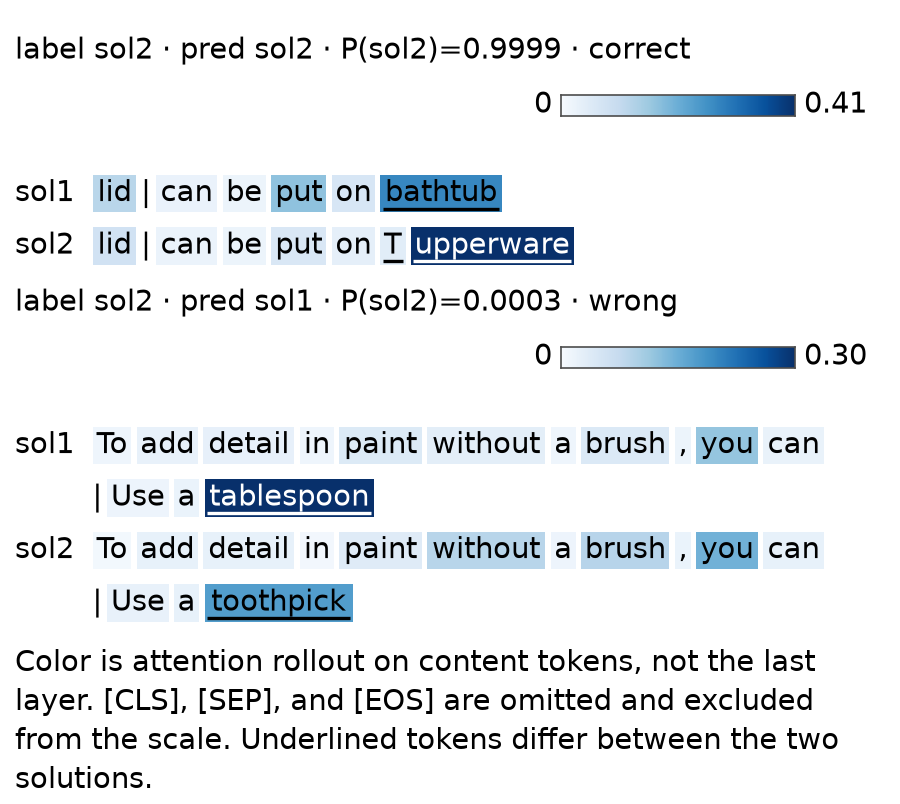

**Four validation examples. Rollout only. Differing tokens are underlined.** `reports/attention/figA_examples_compact.png`

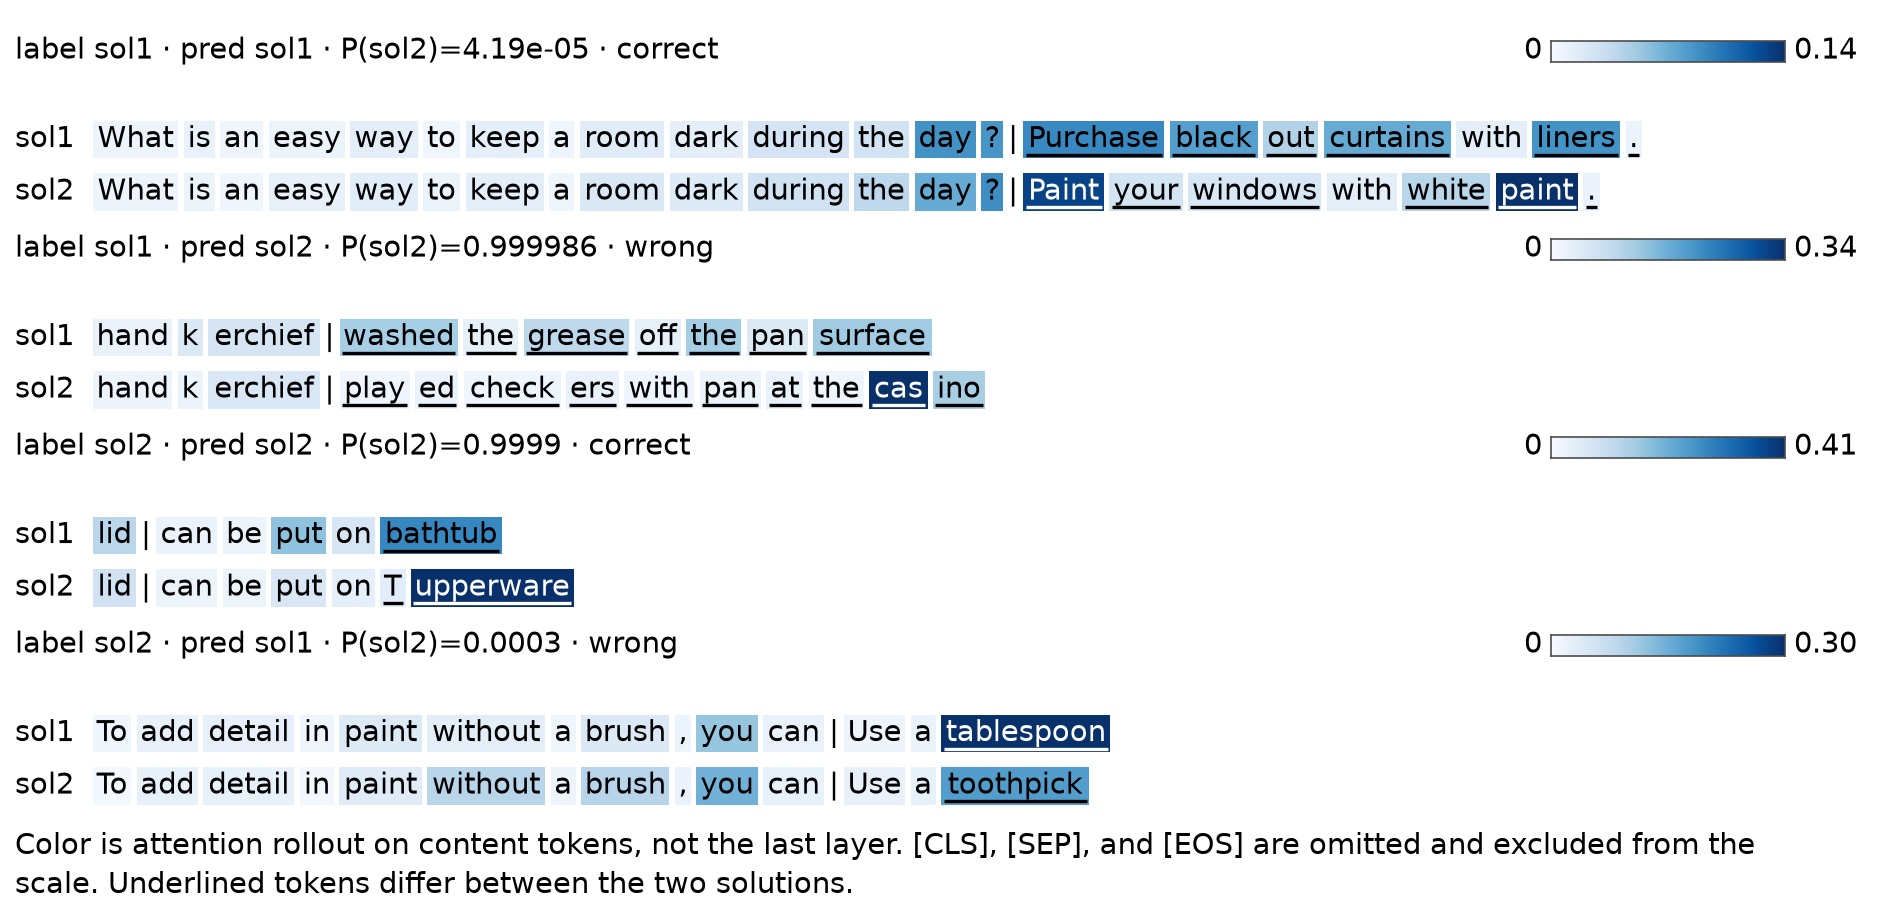

**Region shares, and validation accuracy by word-level distance.** `reports/attention/figB_share_and_accuracy_compact.png`

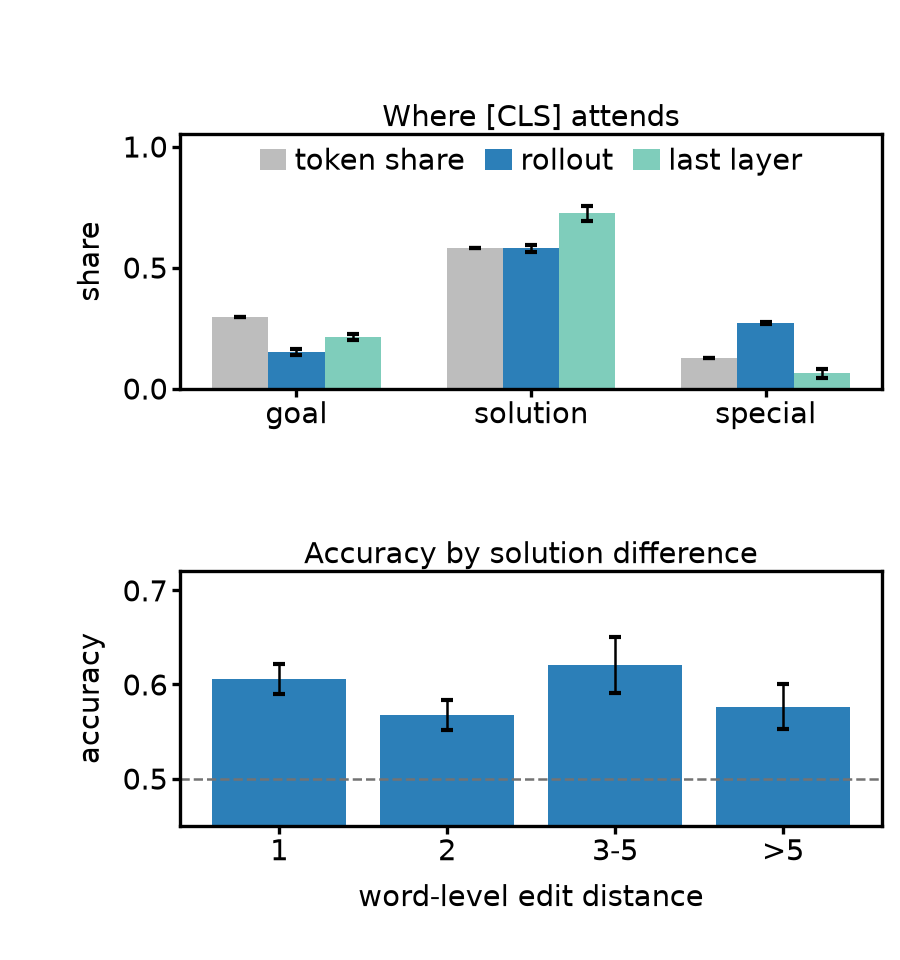

,region,token share,rollout,last layer
0,goal,0.294 ± 0.000,0.150 ± 0.013,0.213 ± 0.013
1,solution,0.581 ± 0.000,0.579 ± 0.016,0.724 ± 0.032
2,special,0.125 ± 0.000,0.271 ± 0.003,0.064 ± 0.018


,outcome,n (mean),rollout,token share
0,correct,566.3,0.116 ± 0.004,0.074 ± 0.001
1,incorrect,392.7,0.120 ± 0.003,0.081 ± 0.002


,seed,outcome,n,rollout,token share
0,4012,correct,564,"0.114 [0.106, 0.122]","0.074 [0.070, 0.079]"
1,4012,incorrect,395,"0.117 [0.107, 0.128]","0.081 [0.075, 0.087]"
2,4013,correct,565,"0.113 [0.105, 0.120]","0.073 [0.069, 0.078]"
3,4013,incorrect,394,"0.120 [0.110, 0.130]","0.083 [0.077, 0.088]"
4,4014,correct,570,"0.121 [0.113, 0.128]","0.075 [0.071, 0.080]"
5,4014,incorrect,389,"0.123 [0.114, 0.134]","0.079 [0.074, 0.086]"


,grouping,bin,n,accuracy
0,n_diff,1,568,0.606 ± 0.016
1,n_diff,2,391,0.568 ± 0.016
2,n_diff,3-5,334,0.621 ± 0.030
3,n_diff,>5,313,0.576 ± 0.024
4,length,5–20,410,0.587 ± 0.007
5,length,20–29,396,0.600 ± 0.012
6,length,29–43,404,0.621 ± 0.013
7,length,43–498,396,0.567 ± 0.015


,seed,n,delete top word,delete random word,top word is a differing word
0,4012,1606,-0.0573,-0.0082,0.392
1,4013,1606,-0.0387,-0.0059,0.402
2,4014,1606,-0.0242,-0.0061,0.402
3,mean ± sd,1606,-0.040 ± 0.017,-0.007 ± 0.001,0.398 ± 0.006


In [63]:
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

RUN_ATTENTION = False
if RUN_ATTENTION:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "scripts.analysis.attention_analysis",
            "--seeds", "4012", "4013", "4014",
            "--out", "reports/attention",
        ],
        check=True,
    )

attention_dir = Path("reports/attention")
figures = [
    (
        "figA_examples_single_compact.png",
        "Single-column examples, rows 1142 and 1296. Rollout only.",
    ),
    (
        "figA_examples_compact.png",
        "Four validation examples. Rollout only. Differing tokens are underlined.",
    ),
    (
        "figB_share_and_accuracy_compact.png",
        "Region shares, and validation accuracy by word-level distance.",
    ),
]
for filename, caption in figures:
    display(Markdown(f"**{caption}** `{attention_dir / filename}`"))
    display(Image(filename=str(attention_dir / filename)))


def fmt_ms(values, digits=3):
    mean, std = mean_std(values)
    return f"{mean:.{digits}f} ± {std:.{digits}f}"


share = pd.read_csv(attention_dir / "goal_solution_share.csv")
share_rows = []
for region in ("goal", "solution", "special"):
    token = share.loc[(share["region"] == region) & (share["source"] == "rollout"), "token_mean"]
    rollout = share.loc[(share["region"] == region) & (share["source"] == "rollout"), "attention_mean"]
    last = share.loc[(share["region"] == region) & (share["source"] == "last"), "attention_mean"]
    share_rows.append({
        "region": region,
        "token share": fmt_ms(token),
        "rollout": fmt_ms(rollout),
        "last layer": fmt_ms(last),
    })
share_table = pd.DataFrame(share_rows)
display(share_table)

diff = pd.read_csv(attention_dir / "diff_token_attention.csv")
diff_rows = []
for outcome in ("correct", "incorrect"):
    group = diff.loc[diff["outcome"] == outcome]
    diff_rows.append({
        "outcome": outcome,
        "n (mean)": f"{group['n'].mean():.1f}",
        "rollout": fmt_ms(group["attention_mean"]),
        "token share": fmt_ms(group["token_mean"]),
    })
diff_summary = pd.DataFrame(diff_rows)
display(diff_summary)

diff_seed = diff.copy()
diff_seed["rollout"] = [
    f"{mean:.3f} [{low:.3f}, {high:.3f}]"
    for mean, low, high in zip(
        diff_seed["attention_mean"], diff_seed["attention_ci_low"], diff_seed["attention_ci_high"],
    )
]
diff_seed["token share"] = [
    f"{mean:.3f} [{low:.3f}, {high:.3f}]"
    for mean, low, high in zip(
        diff_seed["token_mean"], diff_seed["token_ci_low"], diff_seed["token_ci_high"],
    )
]
display(diff_seed[["seed", "outcome", "n", "rollout", "token share"]])

errors = pd.read_csv(attention_dir / "error_by_diff.csv", dtype={"grouping": str, "bin": str})
first_seed = errors["seed"].min()
order = errors.loc[errors["seed"] == first_seed, ["grouping", "bin"]]
error_rows = []
for grouping, bin_label in order.itertuples(index=False):
    group = errors.loc[(errors["grouping"] == grouping) & (errors["bin"] == bin_label)]
    error_rows.append({
        "grouping": grouping,
        "bin": bin_label,
        "n": int(group["n"].iloc[0]),
        "accuracy": fmt_ms(group["accuracy"]),
    })
error_table = pd.DataFrame(error_rows)
display(error_table)

intervention = pd.read_csv(attention_dir / "intervention.csv")
intervention_view = pd.DataFrame({
    "seed": intervention["seed"],
    "n": intervention["n"],
    "delete top word": intervention["top_mean"].map(lambda value: f"{value:.4f}"),
    "delete random word": intervention["random_mean"].map(lambda value: f"{value:.4f}"),
    "top word is a differing word": intervention["top_is_diff_rate"].map(lambda value: f"{value:.3f}"),
})
intervention_view.loc[len(intervention_view)] = {
    "seed": "mean ± sd",
    "n": int(intervention["n"].iloc[0]),
    "delete top word": fmt_ms(intervention["top_mean"]),
    "delete random word": fmt_ms(intervention["random_mean"]),
    "top word is a differing word": fmt_ms(intervention["top_is_diff_rate"]),
}
display(intervention_view)

expected_share = {
    "goal": ("0.294 ± 0.000", "0.150 ± 0.013", "0.213 ± 0.013"),
    "solution": ("0.581 ± 0.000", "0.579 ± 0.016", "0.724 ± 0.032"),
    "special": ("0.125 ± 0.000", "0.271 ± 0.003", "0.064 ± 0.018"),
}
for region, expected in expected_share.items():
    got = share_table.loc[share_table["region"] == region].iloc[0]
    actual = (got["token share"], got["rollout"], got["last layer"])
    if actual != expected:
        raise AssertionError(f"{region} share {actual} != {expected}")

expected_diff = {
    "correct": ("0.116 ± 0.004", "0.074 ± 0.001"),
    "incorrect": ("0.120 ± 0.003", "0.081 ± 0.002"),
}
for outcome, expected in expected_diff.items():
    got = diff_summary.loc[diff_summary["outcome"] == outcome].iloc[0]
    actual = (got["rollout"], got["token share"])
    if actual != expected:
        raise AssertionError(f"{outcome} diff attention {actual} != {expected}")

expected_error = {
    ("n_diff", "1"): "0.606 ± 0.016",
    ("n_diff", "2"): "0.568 ± 0.016",
    ("n_diff", "3-5"): "0.621 ± 0.030",
    ("n_diff", ">5"): "0.576 ± 0.024",
    ("length", "5–20"): "0.587 ± 0.007",
    ("length", "20–29"): "0.600 ± 0.012",
    ("length", "29–43"): "0.621 ± 0.013",
    ("length", "43–498"): "0.567 ± 0.015",
}
for key, expected in expected_error.items():
    got = error_table.loc[
        (error_table["grouping"] == key[0]) & (error_table["bin"] == key[1]), "accuracy"
    ].item()
    if got != expected:
        raise AssertionError(f"{key} accuracy {got!r} != {expected!r}")

top_text = fmt_ms(intervention["top_mean"])
random_text = fmt_ms(intervention["random_mean"])
diff_rate_text = fmt_ms(intervention["top_is_diff_rate"])
if (top_text, random_text, diff_rate_text) != ("-0.040 ± 0.017", "-0.007 ± 0.001", "0.398 ± 0.006"):
    raise AssertionError(f"intervention {(top_text, random_text, diff_rate_text)}")


## 3.8 Summary

On the test set the frozen Transformer reaches 58.9 ± 0.2 accuracy. The no-attention BiLSTM reaches 58.3 ± 0.5, and the shorter-solution rule reaches 53.2. Zero-shot GPT-2 (61.5) and Qwen2.5-0.5B (69.5), and fine-tuned DistilBERT (62.2 ± 0.8) and RoBERTa-base (70.5 ± 0.5), score higher. Those four models are pretrained and much larger, so they are a reference for a different training regime.

On the validation set, turning positional encoding off or using a single attention head leaves accuracy close to the main model. Turning dropout off lowers accuracy, and that run peaks near epoch 11, with a much larger validation loss by epoch 300. Removing the goal at evaluation lowers accuracy on every seed. The attention rollout puts less mass on the goal than the goal's share of the sequence, which lines up with that sensitivity. The attention weights remain a correlation with the prediction.


In [64]:
import time

elapsed = time.perf_counter() - _SECTION_STARTED
minutes, seconds = divmod(elapsed, 60)
print(f"Section 3 runtime: {elapsed:.1f} s ({int(minutes)} min {seconds:.1f} s)")


Section 3 runtime: 5.8 s (0 min 5.8 s)
